<a href="https://colab.research.google.com/github/rgaratac/dust_tool_test/blob/main/Dust_deduction_tool_full%20copy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Natural Dust service Tool

This notebook presents the **CAMS Natural Dust Service Tool**, which supports EU Member States in identifying and quantifying the contribution of natural dust to measured $PM_{10}$ and $PM_{2.5}$ concentrations, as required under Article 16 of the revised Ambient Air Quality Directive (Directive (EU) 2024/2881). The tool estimates the natural dust contribution and subtracts it from the measured concentrations, yielding dust-corrected surface $PM_{10}$ and $PM_{2.5}$ values.

> AAQD (2024/2881) Article 16: Member states are requested to identify a) zones where exceedances of limit values for a given pollutant are attributable to natural sources and b) average exposure territorial units, where exceedances of the level determined by the average exposure reduction obligations are attributable to natural sources.

The Natural Dust Service Tool implements the EU methodology for natural contributions. Stations are classified as regional background (RB), urban/suburban background (UB) or traffic/industrial hotspots (TH) and paired with a nearby RB (and, for TH, a UB) station. The natural load is quantified at the reference station (Option 1) or by self-calibration of UB stations (Option 2) and subtracted on every natural-event day. The CAMS interim reanalysis dust product is used to identify days affected by natural dust.


# Outline
- [ 1 - Import Packages ](#1)
- [ 2 - Country selection and Threshold settings](#2)
- [ 3 - Download data ](#3)
- [ 4 - Data preparation ](#4)
  - [ 4.6 - Station classification and pairing ](#4.6)
- [ 5 - Flag dust days with CAMS data](#5)
- [ 6 - Calculate the dust contribution](#6)
- [ 7 - Save or load results](#7)
- [ 8 - Visualization](#8)
  - [ 8.4 - Exceedance report ](#8.4)

Created by Jessie Zhang, TNO
          22/05/2026

<a name="1"></a>
## **1 - Import Packages**

Run the cell below to load the required packages and the helper functions. If everything loads correctly, the last line of the output reads:

> util.py has been imported




In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import requests
import os
import glob
import zipfile
import calendar
#!pip install xarray netcdf4
import xarray as xr
!pip install cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
# %pip uninstall plotly -y
# %pip install "plotly>=5.24.0"
from importlib.metadata import version as _pkg_version
# Plotly 6 widgets bundle their own JS, so the maps also render in VS Code.
if int(_pkg_version('plotly').split('.')[0]) < 6:
    %pip install -q "plotly>=6" anywidget
import plotly
import urllib.request
import json
import io
import importlib.util
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
IN_COLAB = importlib.util.find_spec('google.colab') is not None
try:
    # Pin to the latest commit: raw.githubusercontent.com caches 'main' for several minutes.
    _sha = requests.get("https://api.github.com/repos/rgaratac/dust_tool_test/commits/main",
                        headers={"Accept": "application/vnd.github.sha"}, timeout=10).text.strip()
except Exception:
    _sha = ""
raw_base = f"https://raw.githubusercontent.com/rgaratac/dust_tool_test/{_sha if len(_sha) == 40 else 'main'}"
for name in ["util.py", "cams_data_to_eea_daily.py", "pairing.py",
             "natural_contribution.py", "pairing_viz.py", "dust_threshold_sensitivity.py",
             "exceedance_report.py"]:
    # Locally the repo copies are kept, so local edits are not overwritten.
    if IN_COLAB or not Path(name).exists():
        urllib.request.urlretrieve(f"{raw_base}/{name}", Path(name))
import importlib, util, pairing, natural_contribution, pairing_viz, exceedance_report
# Re-running this cell picks up edited modules without restarting the kernel.
for _mod in (util, pairing, natural_contribution, pairing_viz, exceedance_report):
    importlib.reload(_mod)
from util import *
import pairing as pr
import natural_contribution as nc
import pairing_viz as pv
import exceedance_report as er
print(until_check())

util.py has been imported



<details>
<summary><font size="2" color="darkgreen"><b>Troubleshooting</b></font></summary>
Remove <font size="2" color="blue"> <b>%%capture</b></font> and output should show in the end:

> util.py has been imported

If functions are modified in util.py please reload the file use the code below
```
import sys, importlib, os, inspect
import util
importlib.invalidate_caches()
if 'util' in sys.modules:
    del sys.modules['util']
import util
importlib.reload(util)  # extra safety

# Double-check the function exists and from which file it's loaded
print("Has function?", hasattr(util, 'plot_station_timeseries'))
if hasattr(util, 'plot_station_timeseries'):
    print(inspect.getsource(util.plot_station_timeseries)[:400])  # peek at the first lines

```
If one of the modules are not loading  try

```
!pip install <package-name>
```
The interactive map widgets are designed for Google Colab and may not work in VS Code or on an HPC system. In that case, use the static plots in Section 7, entering the column names you want to plot.




<a name="2"></a>
## **2- Country selection and Threshold settings**
Select one or more countries from the table below by listing their codes in `Countries`, then choose the year (`YEAR`), pollutant (`POLLUTANT`), dataset (`dataset`) and time resolution (`EEA_temporal_flag`, `hour` or `day`). `COMPUTE_CAMS_DAILY` builds the CAMS daily mean that matches that choice: UTC days for hourly EEA data, and each station's local day for daily EEA data.
The data only need to be downloaded and processed once. After that, the tool reuses the stored files:

<center>

| Flag | First run | Later runs | What it does |
|---|---|---|---|
| `DOWNLOAD_EEA` | `True` | `False` | Downloads the EEA observations and stores them as a zip file |
| `DOWNLOAD_CAMS` | `True` | `False` | Downloads the CAMS interim reanalysis dust data |
| `COMPUTE_CAMS_DAILY` | `True` | `False` | Builds the daily CAMS product from the hourly zips. `hour` writes a UTC daily grid; `day` writes per-station local-day means. Turned on automatically when `DOWNLOAD_CAMS` is True |
| `LOAD_PARQUET_DATA` | `False` | `True` | Loads the saved Parquet file with the processed results instead of recomputing them |


### Available countries in EEA

| Country Code | Country Name           | Country Code | Country Name           |
|-------------|-------------------------|-------------|-------------------------|
| AD          | Andorra                | IT          | Italy                  |
| AL          | Albania                | LT          | Lithuania              |
| AT          | Austria                | LU          | Luxembourg             |
| BA          | Bosnia and Herzegovina | LV          | Latvia                 |
| BE          | Belgium                | ME          | Montenegro             |
| BG          | Bulgaria               | MK          | North Macedonia        |
| CH          | Switzerland            | MT          | Malta                  |
| CY          | Cyprus                 | NL          | Netherlands            |
| CZ          | Czechia                | NO          | Norway                 |
| DE          | Germany                | PL          | Poland                 |
| DK          | Denmark                | PT          | Portugal               |
| EE          | Estonia                | RO          | Romania                |
| ES          | Spain                  | RS          | Serbia                 |
| FI          | Finland                | SE          | Sweden                 |
| FR          | France                 | SI          | Slovenia               |
| GB          | United Kingdom         | SK          | Slovakia               |
| GR          | Greece                 | XK          | Kosovo                |  
| HR          | Croatia                |             |                         |
| HU          | Hungary                |             |                         |
| IE          | Ireland                |             |                         |
| IS          | Iceland                |             |                         |

</center>

Available EEA datasets:


1.   Verified data (`E1a`): Validated measurements available from 2013, reported annually by countries for the previous year.

2.   Up-to-date data (`E2a`): Unverified measurements transmitted continuously, available from 2023.

E2a daily aggregation deoes not have any station data for 2025.



In [18]:
project_dir          = '.'
YEAR                 = 2025      # int: target year
EEA_temporal_flag    = 'day'    # 'hour' (UTC daily CAMS) or 'day' (local-day CAMS)
dataset              = 'E1a'     # E1a or E2a
POLLUTANT            = 'PM2.5'
EEA_folder_path      = f'EEA_{POLLUTANT}/{YEAR}/{dataset}/{EEA_temporal_flag}'
VAR                  = 'dust'
CAMS_folder_path     = f'{project_dir}/IRA_{VAR}/'
DOWNLOAD_EEA         = False
DOWNLOAD_CAMS        = False
COMPUTE_CAMS_DAILY   = False
USE_GOOGLE_DRIVE     = IN_COLAB  # Colab: keep outputs on Drive. Locally outputs go to project_dir.
Countries            = ["ES"]
# full list of countries
#Countries            =  ["AD", "AL", "AT", "BA", "BE", "BG", "CH", "CY", "CZ", "DE", "DK", "EE", "ES", "FI", "FR", "GB", "GR", "HR", "HU", "IE", "IS", "IT", "LT", "LU", "LV", "ME", "MK", "MT", "NL", "NO", "PL", "PT", "RO", "RS", "SE", "SI", "SK", "XK"]
LOAD_PARQUET_DATA    = True # if False then new data will be saved, only use it as True when everything has been computed

import cams_data_to_eea_daily as cams_daily

# Falls back to project_dir when Drive cannot be mounted (e.g. running locally).
OUTPUT_DIR, USE_GOOGLE_DRIVE = cams_daily.resolve_output_dirs(project_dir, USE_GOOGLE_DRIVE and IN_COLAB)
gdrive_output_dir = OUTPUT_DIR  # older cells use this name
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f'Output folder: {os.path.abspath(OUTPUT_DIR)}')

# DOWNLOAD_CAMS brings new hourly files, so the daily product has to be rebuilt.
# Which average is used follows EEA_temporal_flag (hour = UTC day, day = station local day).
_run = cams_daily.resolve_run_flags(
    download_eea=DOWNLOAD_EEA,
    download_cams=DOWNLOAD_CAMS,
    compute_cams_daily=COMPUTE_CAMS_DAILY,
    load_parquet=LOAD_PARQUET_DATA,
    eea_temporal_flag=EEA_temporal_flag,
)
DOWNLOAD_EEA = _run['download_eea']
DOWNLOAD_CAMS = _run['download_cams']
COMPUTE_CAMS_DAILY = _run['compute_cams_daily']
LOAD_PARQUET_DATA = _run['load_parquet']
for _note in _run['notes']:
    print(_note)
if _run['local_day']:
    print("EEA daily data: CAMS daily means use each station's local day.")
else:
    print('EEA hourly data: CAMS daily means use UTC days.')

Google Drive output directory: /content/drive/MyDrive/CAMS_Tool_output
Output folder: /content/drive/MyDrive/CAMS_Tool_output
EEA daily data: CAMS daily means use each station's local day.


**Thresholds, limit values and method parameters**

The parameters can be adjusted below, for example to reflect future changes in the guidelines or limit values:

*   `CAMS_dust_threshold`: CAMS dust concentration (µg/m³) above which a day is flagged as a natural-event (dust) day.
*   `PM10_DAILY_LIMIT`, `PM25_DAILY_LIMIT`, `PM10_ANNUAL_LIMIT`, `PM25_ANNUAL_LIMIT`: limit values (µg/m³). The daily PM10 default is 45 µg/m³ (Directive (EU) 2024/2881); set 50 to use the previous limit. `POLLUTANT_daily_threshold` and `POLLUTANT_annual_threshold` follow `POLLUTANT`.
*   `Station_Temporal_coverage`: minimum annual data coverage (%) required for an EEA station to be included.
*   `Basline_MA_days`: kept for the output file names of earlier runs. The new methods use the windows below.

Station pairing (section 4.6):

*   `MAX_RB_DISTANCE_KM`, `MAX_RB_ALTITUDE_DIFF_M`: a regional background (RB) station is a suitable reference only within this horizontal distance and altitude difference.
*   `MAX_UB_DISTANCE_KM`: maximum distance between a traffic/industrial (TH) station and its urban background (UB) reference.
*   `PAIR_SAME_COUNTRY`: only pair stations of the same country.
*   `USE_USER_PAIRING`: when True and `station_pairing_user.csv` exists in the output folder, it replaces the default pairing.
*   `REAPPLY_PAIRING_ON_LOAD`: when results are loaded from Parquet, recompute the deduction with the current pairing (the first and last 15 days of the year then have a shorter Option 1 window).

Methods (section 6):

*   `OPTION1_HALF_WINDOW` (15) and `OPTION2_HALF_WINDOW` (3): days before and after an event day (or an episode for Option 2) in the reference window. Event days are always excluded.
*   `REFERENCE_PERCENTILE` (50): percentile of the reference window.
*   `MIN_REFERENCE_DAYS_OPTION1`, `MIN_REFERENCE_DAYS_OPTION2`: minimum valid reference days; otherwise the day is flagged `insufficient_reference` and nothing is subtracted.

In [19]:
##################User Editable######################
CAMS_dust_threshold         = 5         # unit: µg/m3 total dust

# Limit values, µg/m3 (Directive (EU) 2024/2881). Use PM10_DAILY_LIMIT = 50 for the previous limit.
PM10_DAILY_LIMIT            = 45
PM25_DAILY_LIMIT            = 25
PM10_ANNUAL_LIMIT           = 20
PM25_ANNUAL_LIMIT           = 10

Station_Temporal_coverage   = 65        # in % of temporal coverage per whole year for each EEA station
Basline_MA_days             = 6         # only used in the output file names

# Station pairing
MAX_RB_DISTANCE_KM          = 100
MAX_RB_ALTITUDE_DIFF_M      = 500
MAX_UB_DISTANCE_KM          = 50
PAIR_SAME_COUNTRY           = True
USE_USER_PAIRING            = False     # True: use station_pairing_user.csv from the output folder
USER_PAIRING_FILE           = 'station_pairing_user.csv'
REAPPLY_PAIRING_ON_LOAD     = True

# Natural-contribution methods
OPTION1_HALF_WINDOW         = 15
OPTION2_HALF_WINDOW         = 3
REFERENCE_PERCENTILE        = 50
MIN_REFERENCE_DAYS_OPTION1  = 10
MIN_REFERENCE_DAYS_OPTION2  = 3
##################STOP Editing######################

LIMITS = nc.LimitValues(PM10_DAILY_LIMIT, PM25_DAILY_LIMIT, PM10_ANNUAL_LIMIT, PM25_ANNUAL_LIMIT)
POLLUTANT_daily_threshold   = LIMITS.daily(POLLUTANT)
POLLUTANT_annual_threshold  = LIMITS.annual(POLLUTANT)
PAIRING_LIMITS = pr.PairingLimits(
    max_rb_distance_km=MAX_RB_DISTANCE_KM,
    max_rb_altitude_diff_m=MAX_RB_ALTITUDE_DIFF_M,
    max_ub_distance_km=MAX_UB_DISTANCE_KM,
    same_country=PAIR_SAME_COUNTRY,
)
METHOD_PARAMS = nc.MethodParams(
    option1_half_window=OPTION1_HALF_WINDOW,
    option2_half_window=OPTION2_HALF_WINDOW,
    percentile=REFERENCE_PERCENTILE,
    min_reference_days_option1=MIN_REFERENCE_DAYS_OPTION1,
    min_reference_days_option2=MIN_REFERENCE_DAYS_OPTION2,
)
print(f'{POLLUTANT}: daily limit {POLLUTANT_daily_threshold} µg/m3, annual limit {POLLUTANT_annual_threshold} µg/m3')

PM2.5: daily limit 25 µg/m3, annual limit 10 µg/m3


<a name="3"></a>
## **3- Download data**

This section downloads the two datasets the tool needs:


*   **EEA observations** of the selected pollutant, from the EEA air quality download service
*   **CAMS interim reanalysis dust**, from the Copernicus Atmosphere Data Store (ADS)

Both downloads only need to run once. The files are stored in your output folder (CAMS_Tool_output on Google Drive, or the project folder when USE_GOOGLE_DRIVE = False) and reused in later runs.


**3.1 EEA observations**

When `DOWNLOAD_EEA` = True, the cell below requests the EEA data for the selected countries, pollutant, dataset, year and time resolution. The download covers 14 December of the previous year to 31 December of the selected year, so that the background concentration can also be calculated for the first days of the year.

The EEA service prepares the file on request. Large requests (many countries or hourly data) can take several minutes. Daily requests use the same API, dataset ids (`E2a` = 1, `E1a` = 2), countries, pollutant and year span, with `aggregationType` set to `day`.

The data are saved as a zip file named {dataset}_{POLLUTANT}_{EEA_temporal_flag}_{YEAR}.zip and extracted to EEA_{POLLUTANT}/{YEAR}/{dataset}/{EEA_temporal_flag}. If a zip file for the same selection already exists, it is replaced by the new download. When DOWNLOAD_EEA = False, the cell extracts the zip file saved in a previous run.

In [20]:
zip_target_path = cams_daily.eea_zip_path(OUTPUT_DIR, POLLUTANT, EEA_temporal_flag, dataset, YEAR)
local_extract_path = EEA_folder_path
os.makedirs(os.path.dirname(zip_target_path), exist_ok=True)
os.makedirs(local_extract_path, exist_ok=True)

if (DOWNLOAD_EEA):
    from datetime import datetime

    # If the file exists and DOWNLOAD_EEA is True, remove it before proceeding with download
    if os.path.exists(zip_target_path):
        os.remove(zip_target_path)
        print(f"Removed existing EEA data from {zip_target_path}. Proceeding with new download.")

    apiUrl = "https://eeadmz1-downloads-api-appservice.azurewebsites.net/"
    endpoint = "ParquetFile/async"

    # 1: E2a (UTD), 2: E1a (Verified), 3: Historical
    dataset_mapping = {
        'E2a': 1,
        'UTD': 1,
        'E1a': 2,
        'Historical': 3
    }
    eea_dataset_id = dataset_mapping.get(dataset, 2)

    request_body = {
        "countries": Countries,
        "cities": [],
        "pollutants": [POLLUTANT],
        "dataset": eea_dataset_id,
        "dateTimeStart": f"{YEAR-1}-12-14T00:00:00Z",
        "dateTimeEnd": f"{YEAR}-12-31T23:59:59Z",
        "aggregationType": EEA_temporal_flag,
        "email": ""
    }

    response = requests.post(f"{apiUrl}{endpoint}", json=request_body)
    downloadFile = response.text
    print(f"Requesting download from: {downloadFile}")

    t_start = datetime.now()
    while True:
        if (datetime.now() - t_start).total_seconds() > 3600:  # stop after 1 hour if the file has not been created
            break
        parquetResponse = requests.get(downloadFile)
        if parquetResponse.status_code == 404:
            time.sleep(20)
        else:
            break

    with open(zip_target_path, "wb") as fp:
        fp.write(parquetResponse.content)

    print(f"Download Successful: {zip_target_path}")

    with zipfile.ZipFile(zip_target_path, 'r') as zip_ref:
        zip_ref.extractall(local_extract_path)
    print(f"EEA data extracted to {local_extract_path}")
elif os.path.exists(zip_target_path):
    print(f"DOWNLOAD_EEA is False. Extracting existing zip found at: {zip_target_path}")
    with zipfile.ZipFile(zip_target_path, 'r') as zip_ref:
        zip_ref.extractall(local_extract_path)
    print(f"Data extracted to {local_extract_path}")
else:
    print(f"DOWNLOAD_EEA is False, but no existing zip file was found at {zip_target_path}. Please set DOWNLOAD_EEA to True.")

DOWNLOAD_EEA is False. Extracting existing zip found at: /content/drive/MyDrive/CAMS_Tool_output/EEA_PM2.5/day/E1a_PM2.5_day_2025.zip
Data extracted to EEA_PM2.5/2025/E1a/day


**3.2 CAMS dust data**

**3.2.1. Set up your ADS API key**

Downloading CAMS data requires a free account on the Copernicus Atmosphere Data Store (ADS). Before the first download:



1.   Log in to the ADS and copy your API key from your profile page. See the API setup guide for details (https://cds.climate.copernicus.eu/how-to-api).
2.   Accept the licence of the CAMS European air quality reanalyses dataset on its download page. Requests fail until the licence has been accepted.
3. Run the cell below and paste your API key when prompted. The key is saved in ~/.cdsapirc and is not requested again.

To replace an existing key, uncomment the !rm ~/.cdsapirc line and run the cell again. If error appeared please try !pip install --user "cdsapi>=0.7.7"
.
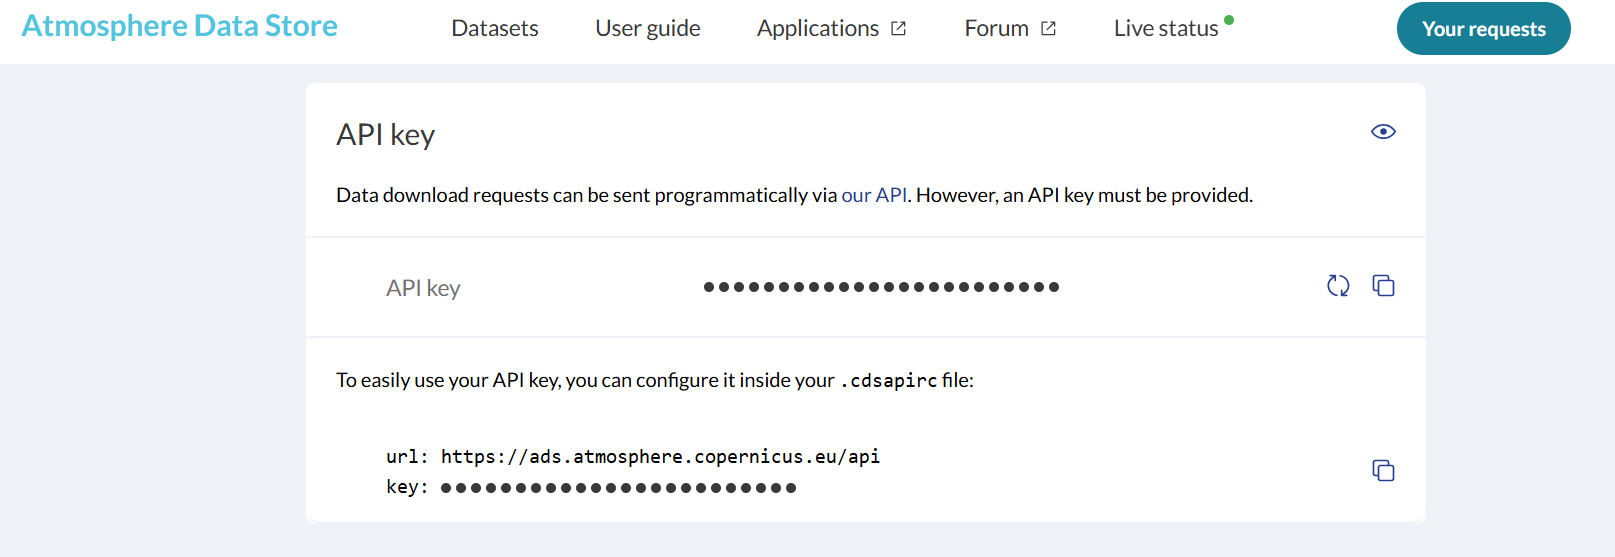

In [21]:
if (DOWNLOAD_CAMS):
  if importlib.util.find_spec('cdsapi') is None:
    %pip install -q "cdsapi>=0.7.7"
  path = os.path.expanduser('~/.cdsapirc')
  # To replace an existing key, delete ~/.cdsapirc and run this cell again.
  if os.path.exists(path):
      print(f"Skipping: Configuration file already exists at {path}")
  else:
    from getpass import getpass
    api_key = getpass("Enter your Copernicus ADS API Key: ").strip()
    with open(path, 'w') as f:
        f.write(f"url: https://ads.atmosphere.copernicus.eu/api\nkey: {api_key}\n")
    print(f"\nSuccess! .cdsapirc has been created at {path}")

**3.2.2. Download the CAMS dust data**

CAMS zip files are stored in the output folder (`IRA_dust/` on Google Drive when `USE_GOOGLE_DRIVE` is True, otherwise in the project folder). Hourly NetCDF is extracted from those zips onto local disk only when `COMPUTE_CAMS_DAILY` is True, and the NetCDF is not copied to Drive.

`DOWNLOAD_CAMS = True` sets `COMPUTE_CAMS_DAILY = True`. An existing zip is reused; only a missing zip is downloaded. The daily mean itself depends on `EEA_temporal_flag`: a UTC grid for hourly EEA data, and a local-day mean at each station for daily EEA data.

When `COMPUTE_CAMS_DAILY` is False, this cell does not extract the zips. Later cells load the daily CAMS file saved by a previous run.


In [23]:
if (DOWNLOAD_CAMS):
    ### First make sure cdsapi can be loaded correctly
    import site
    from importlib import reload

    # Force Python to look at the newly installed packages
    reload(site)

    try:
        import cdsapi
        # Attempt to initialize a client to verify it works
        client = cdsapi.Client(quiet=True)
        print("Success! cdsapi is now imported and the client is initialized.")
    except ImportError:
        print("Still unable to import. Please try restarting the session via: Runtime -> Restart session")
    except Exception as e:
        print(f"cdsapi is imported but failed to initialize: {e}")
    #### end of loading


VAR = "dust"
import importlib
import cams_data_to_eea_daily as cams_daily
importlib.reload(cams_daily)

persistent_dir = gdrive_output_dir if USE_GOOGLE_DRIVE else project_dir
if DOWNLOAD_CAMS or COMPUTE_CAMS_DAILY:
    # Zips stay in the output folder. Hourly NetCDF is extracted locally for this run only.
    cams_daily.download_and_extract_cams(
        project_dir,
        persistent_dir,
        YEAR,
        VAR,
        download=DOWNLOAD_CAMS,
        extract=COMPUTE_CAMS_DAILY,
    )
else:
    print("COMPUTE_CAMS_DAILY is False. Zips are not extracted; the saved daily CAMS file is used later.")


COMPUTE_CAMS_DAILY is False. Zips are not extracted; the saved daily CAMS file is used later.


<a name="4"></a>
## **4- Data preparation**

In this step, the EEA observations and station metadata are loaded and filtered for validity and verification status.



### **4.1 Filter for validity and verification**

Only measurements with validity = 1 (valid) and verification = 1 or 2 (verified or preliminary verified) are kept. Negative values are also removed. The EEA definitions are:

<center>

#### Validity

|ID     | Label                                       | Status    | Status Modified | Notation |
|-------|---------------------------------------------|-----------|-----------------|----------|
| -99   | Not valid due to station maintenance or calibration       | Valid           | 22.03.2013 | -99 |
| -1    | Not valid                                                 | Valid           | 22.03.2013 | -1  |
| 1     | Valid                                                     | Valid           | 22.03.2013 | 1   |
| 2     | Valid, but below detection limit measurement value given  | Valid           | 22.03.2013 | 2   |
| 3     | Valid, but below detection limit and number replaced by 0.5*detection limit | Valid           | 22.03.2013 | 3   |
| 4     | Valid (Ozone only) using CCQM.O3.2019                     | Valid           | 04.07.2024 | 4   |


#### Verification
| Id | Label                  | Status | Status Modified | Notation |
|----|------------------------|--------|-----------------|----------|
| 1  | Verified              | Valid  | 22.03.2013      | 1        |
| 2  | Preliminary verified  | Valid  | 22.03.2013      | 2        |
| 3  | Not verified          | Valid  | 22.03.2013      | 3        |
 <br>


</center>

### **4.2 Filter temporal range**
Only stations with data for the selected year are kept. The pre-downloaded dataset also covers some days before and after the selected year, so that moving averages can be calculated at the start and end of the year. EEA hourly data are provided in CET (UTC+1) and are converted to UTC before being aggregated to daily means.

EEA hourly data are provided in CET (fixed UTC+1, no daylight-saving shift) and `eea_to_utc` converts them to UTC before the daily mean. EEA daily data are different: `Start` is the station's local time, taken from the `Timezone` label in `DataExtract.csv` (`UTC`, `UTC+01`, `UTC-04`, and so on). Those stamps are not passed through `eea_to_utc`. When `EEA_temporal_flag` is `day` and `COMPUTE_CAMS_DAILY` is True, section 4.5 averages CAMS (UTC) over the matching local day: local day D is the UTC window `[D 00:00 - offset, D+1 00:00 - offset)`.


In [24]:
import gc

def eea_to_utc(series: pd.Series, source_tz: str = "CET") -> pd.Series:
    s = pd.to_datetime(series, errors="coerce")
    def _localize_if_naive(x):
        if pd.isna(x): return x
        return x.tz_localize("Etc/GMT-1") if x.tzinfo is None else x
    return s.apply(_localize_if_naive).dt.tz_convert("UTC")

if EEA_temporal_flag == 'hour' and not(LOAD_PARQUET_DATA):
    search_path = os.path.join(EEA_folder_path, "**/*.parquet")
    parquet_files = glob.glob(search_path, recursive=True)

    if parquet_files:
        needed_cols = ['Value', 'Validity', 'Verification', 'AggType', 'Start', 'Samplingpoint', 'Unit', 'Pollutant']

        dataframes = []
        for file in parquet_files:
            df_tmp = pd.read_parquet(file, columns=needed_cols)
            df_tmp['Value'] = pd.to_numeric(df_tmp['Value'], errors='coerce').astype('float32')
            df_tmp['Samplingpoint'] = df_tmp['Samplingpoint'].astype('category')
            df_tmp['Pollutant'] = df_tmp['Pollutant'].astype('category')
            dataframes.append(df_tmp)

        obs = pd.concat(dataframes, ignore_index=True)
        del dataframes
        gc.collect()

        obs['Validity'] = pd.to_numeric(obs['Validity'], errors='coerce').astype('int8')
        obs['Verification'] = pd.to_numeric(obs['Verification'], errors='coerce').astype('int8')
        obs['AggType'] = obs['AggType'].astype('category')
        obs['Start'] = eea_to_utc(obs['Start'])

        print(f"Observations Before filtering: {obs.shape[0]:,}")

        # Keep valid, verified, hourly, non-negative values
        mask = (obs['Validity'] == 1) & (obs['Verification'] < 3) & (obs['AggType'].str.lower() == 'hour') & (obs['Value'] >= 0)
        obs = obs.loc[mask].drop(columns=['Verification', 'AggType'], errors='ignore')

        obs['day'] = obs['Start'].dt.floor('D')

        hourly_to_daily_eea = (
            obs.groupby(['Pollutant', 'day', 'Samplingpoint'], sort=True, observed=False)
            .agg(daily_mean=('Value', 'mean'), n_hours=('Value', 'count'), unit=('Unit', 'first'))
            .reset_index()
        )

        # Only keep full 24-hour days to ensure daily mean quality
        hourly_to_daily_eea = hourly_to_daily_eea[hourly_to_daily_eea['n_hours'] == 24]
        print(f"Final stations processed: {len(hourly_to_daily_eea['Samplingpoint'].unique())}")

        del obs
        gc.collect()
    else:
        print("Error: No parquet files found.")
elif EEA_temporal_flag == 'day' and not(LOAD_PARQUET_DATA):
    # Daily EEA timestamps are station local time. Do not call eea_to_utc:
    # that helper treats every naive stamp as fixed UTC+1 and would move a
    # UTC+2 station onto the previous UTC date.
    import importlib
    importlib.reload(cams_daily)
    hourly_to_daily_eea = cams_daily.load_and_filter_eea_daily(EEA_folder_path, temporal_flag='day')
    print(f"Final stations processed: {hourly_to_daily_eea['Samplingpoint'].nunique()}")

### **4.3 Load and merge station metadata**

The EEA observations identify each station only by its sampling point ID. The station metadata add the latitude, longitude, altitude and time zone of each station, which are needed to match the stations with the CAMS dust data.

Before running this step, download the metadata file manually:




1.   Open the EEA Air Quality Viewer and download the station metadata as a CSV file (https://discomap.eea.europa.eu/App/AQViewer/index.html?fqn=Airquality_Dissem.b2g.measurements).
2.   Name the file DataExtract.csv.
3.   Save it in your output folder (CAMS_Tool_output on Google Drive, or the project folder when USE_GOOGLE_DRIVE = False).

In [25]:
import calendar
import util

# Inject calendar into the util module namespace to resolve NameError
util.calendar = calendar

if EEA_temporal_flag in ('hour', 'day') and not(LOAD_PARQUET_DATA):
    df_processed = filter_daily_by_coverage(hourly_to_daily_eea, reference_year=YEAR, min_pct=Station_Temporal_coverage, keep_coverage_columns=False)

    # Flag exceedance days with concentration above threshold
    df_processed['Exceedance'] = df_processed['daily_mean'] > POLLUTANT_daily_threshold

    print(f'Total stations found in dataset: {len(df_processed["Samplingpoint"].unique())}')

    _metadata_candidates = [
        os.path.join(OUTPUT_DIR, 'DataExtract.csv'),
        os.path.join(project_dir, 'DataExtract.csv'),
        os.path.join(project_dir, 'Data', 'DataExtract.csv'),
    ]
    metadata_path = next((p for p in _metadata_candidates if os.path.exists(p)), None)

    if metadata_path:
        metadata = pd.read_csv(metadata_path, low_memory=False)
        metadata['Samplingpoint'] = metadata['Air Quality Station EoI Code'].str[:2] + '/' + metadata['Sampling Point Id']
        stations_geo = metadata[['Samplingpoint', 'Longitude', 'Latitude', 'Altitude', 'Timezone']].drop_duplicates(subset=['Samplingpoint'])
        df_processed = df_processed.merge(stations_geo, on='Samplingpoint', how='left')
        print(f"Metadata successfully merged from: {metadata_path}")
    else:
        print(f"Warning: DataExtract.csv not found in {_metadata_candidates}. Skipping spatial merge.")

In [26]:
# # Re-run the metadata merge with the local file
# if os.path.exists(local_metadata):
#     metadata = pd.read_csv(local_metadata, low_memory=False)
#     metadata['Samplingpoint'] = metadata['Air Quality Station EoI Code'].str[:2] + '/' + metadata['Sampling Point Id']
#     stations_geo = metadata[['Samplingpoint', 'Longitude', 'Latitude', 'Altitude', 'Timezone']].drop_duplicates(subset=['Samplingpoint'])

#     # Merge onto the processed dataframe (using the 0-pct version created previously)
#     df_processed = df_processed.merge(stations_geo, on='Samplingpoint', how='left')
#     print(f"Metadata successfully merged. Valid stations with coords: {df_processed['Longitude'].notna().sum()}")
# else:
#     print("Local metadata file missing, please check if the copy step succeeded.")

### **4.4 Compute daily mean CAMS dust**

The cell below converts the hourly CAMS dust data downloaded in Section 3 into daily mean dust concentrations over the whole CAMS domain.


*   When `COMPUTE_CAMS_DAILY` = True: the monthly NetCDF files for the selected year are combined into one hourly dataset and averaged to daily means. Days are defined in UTC, matching the daily means computed from the EEA observations in 4.1. The result is saved as cams_dust_{YEAR}_daily_mean.nc in the IRA_dust folder.
*   When `COMPUTE_CAMS_DAILY` = False: the daily mean file saved in a previous run is loaded instead.


**Memory note:** Computing the daily means for the full CAMS domain may exceed the memory available on Google Colab. If so, run this step once on a local machine or an HPC system and copy the saved daily mean file to your output folder.

With `EEA_temporal_flag = 'day'` this full-domain UTC grid is skipped. Local-day means are built in section 4.5, one UTC day at a time and only at station coordinates, then cached as Parquet under `IRA_dust/` on Google Drive (or in the project folder). A later run reuses those files when they are already there.


In [27]:
##############################################
##############cams data for hourly############
##############################################
if EEA_temporal_flag=='hour' and not(LOAD_PARQUET_DATA):
    # Target output file path
    if USE_GOOGLE_DRIVE:
        daily_cams_path = os.path.join(gdrive_output_dir, f'IRA_{VAR}/cams_dust_{YEAR}_daily_mean.nc')
    else:
        daily_cams_path = os.path.join(project_dir, f"IRA_{VAR}/cams_dust_{YEAR}_daily_mean.nc")

    # Check if we should compute or just load
    if COMPUTE_CAMS_DAILY:
        netcdf_files = np.sort(glob.glob(os.path.join(project_dir, f'IRA_{VAR}/cams.eaq.ira.ENSa.dust*%s*.nc'%(YEAR))))
        print(f"Found {len(netcdf_files)} source files for processing.")

        datasets = []
        for f in netcdf_files:
            try:
                # Use chunks to enable dask-backed lazy loading to save RAM
                ds = xr.open_dataset(f, chunks={'time': 24, 'lat': 100, 'lon': 100})
                datasets.append(ds)
            except Exception as e:
                print(f"Error opening {f}: {e}")

        if datasets:
            print("Aligning and combining datasets...")
            master_lat = datasets[0].lat
            master_lon = datasets[0].lon

            aligned_ds = []
            for ds in datasets:
                if not (ds.lat.equals(master_lat) and ds.lon.equals(master_lon)):
                    ds = ds.interp(lat=master_lat, lon=master_lon, method="nearest")
                aligned_ds.append(ds)

            cams = xr.concat(aligned_ds, dim='time').sortby('time')

            print("Resampling to daily mean...")
            daily_cams = cams.resample(time='1D').mean(keep_attrs=False).compute()

            # Strip attributes to prevent UnicodeEncodeError during save
            daily_cams.attrs = {}
            for var in daily_cams.variables:
                daily_cams[var].attrs = {}

            os.makedirs(os.path.dirname(daily_cams_path), exist_ok=True)
            print(f"Saving processed file to {daily_cams_path}...")
            daily_cams.to_netcdf(daily_cams_path)
            print(f"Saved daily means successfully.")
            cams.close()
        else:
            print("No source datasets were found to process.")
    else:
        if os.path.exists(daily_cams_path):
            print(f"Loading existing daily mean file from: {daily_cams_path}")
            # Use chunks here even when loading the processed file
            daily_cams = xr.open_mfdataset(daily_cams_path, chunks={'time': 'auto'})
            print(f'cams dust unit: {daily_cams["dust"].attrs.get("unit", "N/A")}')
            print(f'cams dust dimension: {daily_cams["dust"].dims}')
        else:
            print(f"Daily mean file not found and COMPUTE_CAMS_DAILY is False.")
elif EEA_temporal_flag == 'day' and not(LOAD_PARQUET_DATA):
    print(
        "Skipping the UTC daily CAMS grid. Section 4.5 builds one local-day "
        "mean per station from hourly CAMS, in chunks, and caches it on Drive."
    )


### **4.5 Match CAMS dust to each station**

Daily CAMS dust concentrations are interpolated to each station location. The result is a single table with one row per station and day, combining the measured daily mean, the exceedance flag and the CAMS dust concentration.

On the hourly path the UTC daily grid is interpolated with `add_cams_daily_dust_by_station`. On the daily path (`EEA_temporal_flag = 'day'`) the notebook calls `add_cams_local_daily_dust` in `cams_data_to_eea_daily.py`. That joins on the local calendar date, not on the nearest UTC day. `COMPUTE_CAMS_DAILY` decides whether that product is rebuilt; the EEA time resolution decides which average is built. The dust flag, background median, corrected concentration, station summary and plots below are unchanged.


In [28]:
if EEA_temporal_flag == 'hour' and not(LOAD_PARQUET_DATA):
    # cams: your xarray.Dataset with hourly dust
    # df_processed: your daily DataFrame
    print('Filtering stations outside CAMS domain and interpolating CAMS data...')

    # 1. Get CAMS spatial bounds
    lat_min, lat_max = daily_cams.lat.min().item(), daily_cams.lat.max().item()
    lon_min, lon_max = daily_cams.lon.min().item(), daily_cams.lon.max().item()

    # 2. Filter df_processed to only include stations within the CAMS domain
    # This prevents interpolation errors and ensures data consistency
    stations_before = len(df_processed['Samplingpoint'].unique())
    df_processed = df_processed[
        (df_processed['Latitude'] >= lat_min) & (df_processed['Latitude'] <= lat_max) &
        (df_processed['Longitude'] >= lon_min) & (df_processed['Longitude'] <= lon_max)
    ].copy()
    stations_after = len(df_processed['Samplingpoint'].unique())

    print(f"Stations filtered: {stations_before - stations_after} removed, {stations_after} remain within CAMS domain.")

    # 3. Interpolate cams data to the remaining station locations
    df = add_cams_daily_dust_by_station(
        cams_ds=daily_cams,
        df=df_processed,
        var_name='dust',
        time_col='day',
        lat_col='Latitude',
        lon_col='Longitude',
        station_col='Samplingpoint',
        spatial_method='linear'
    )
    display(df.head())
elif EEA_temporal_flag == 'day' and not(LOAD_PARQUET_DATA):
    import importlib
    import cams_data_to_eea_daily as cams_daily
    importlib.reload(cams_daily)
    cams_cache_dir = gdrive_output_dir if USE_GOOGLE_DRIVE else project_dir
    nc_files = cams_daily.list_cams_netcdf(project_dir, cams_cache_dir, VAR, YEAR)
    print(f"CAMS files for local-day means: {len(nc_files)}")
    print("Building CAMS daily dust on each station local day (one UTC day of the grid at a time).")
    df = cams_daily.add_cams_local_daily_dust(
        nc_files,
        df_processed,
        var_name=VAR,
        buffer=0.2,
        cache_dir=cams_cache_dir,
        reuse_cache=True,
        recompute_daily=bool(COMPUTE_CAMS_DAILY),
        min_hours=18,
        time_col='day',
        year=YEAR,
    )
    display(df.head())


<a name="4.6"></a>
### **4.6 Station classification and pairing**

Stations are classified from the `Air Quality Station Type` and `Air Quality Station Area` columns of `DataExtract.csv`:

| Class | Rule |
|---|---|
| **RB** regional background | rural* area and background type |
| **UB** urban background | urban or suburban area and background type |
| **TH** hotspot | traffic or industrial type |

#### **4.6.1 Default pairing**

Each non-RB station is paired with the nearest RB station of the same country (`PAIR_SAME_COUNTRY`) within `MAX_RB_DISTANCE_KM` and `MAX_RB_ALTITUDE_DIFF_M`. Each station has at most one reference. A TH station without a suitable RB is paired with the nearest UB station within `MAX_UB_DISTANCE_KM`; without RB or UB it gets no reference. An RB station is its own reference. The method follows from the pairing:

| Method | When | Natural load used |
|---|---|---|
| `option1` | suitable RB | net load at the paired RB |
| `option2` | UB without suitable RB | self-calibration at the station |
| `option2_ub_paired` | TH without suitable RB | Option 2 load of the paired UB |
| `none` | no valid reference | nothing is subtracted |

The default pairing is saved as `station_pairing_default.csv`. With `USE_USER_PAIRING = True` the edited `station_pairing_user.csv` is applied on top of it. The deduction in section 6 always reads the current pairing table, so edits made below are used the next time section 6 runs.

In [29]:
pairing_dir = gdrive_output_dir if USE_GOOGLE_DRIVE else project_dir
pairing_user_path = os.path.join(pairing_dir, USER_PAIRING_FILE)
pairing_default_path = os.path.join(pairing_dir, pr.DEFAULT_PAIRING_FILENAME)
deduction_parquet = cams_daily.deduction_parquet_path(
    pairing_dir, POLLUTANT, dataset, EEA_temporal_flag, YEAR, Basline_MA_days
)

_metadata_candidates = [
    os.path.join(pairing_dir, 'DataExtract.csv'),
    os.path.join(project_dir, 'DataExtract.csv'),
    os.path.join(project_dir, 'Data', 'DataExtract.csv'),
]
pairing_metadata_path = next((p for p in _metadata_candidates if os.path.exists(p)), None)
if pairing_metadata_path is None:
    raise FileNotFoundError(f'DataExtract.csv not found in {_metadata_candidates}')

# Only stations with data can be references: this run's stations, or those in the saved Parquet.
if not LOAD_PARQUET_DATA:
    pairing_station_ids = df['Samplingpoint'].astype(str).unique()
elif os.path.exists(deduction_parquet):
    pairing_station_ids = pd.read_parquet(deduction_parquet, columns=['Samplingpoint'])['Samplingpoint'].astype(str).unique()
else:
    pairing_station_ids = None
    print(f'{deduction_parquet} not found; pairing all stations of the selected countries.')

pairing_metadata = pd.read_csv(pairing_metadata_path, low_memory=False)
stations = pr.build_station_table(
    pairing_metadata, pollutant=POLLUTANT, station_ids=pairing_station_ids, countries=Countries
)
default_pairing = pr.default_pairing(stations, PAIRING_LIMITS)
pr.export_pairing_csv(default_pairing, pairing_default_path)
print(f'{len(stations)} stations classified; default pairing saved to {pairing_default_path}')
n_unknown = int((stations['class'] == 'unknown').sum())
if n_unknown:
    print(f'{n_unknown} station(s) have an unknown area/type and get method none.')

station_pairing, pairing_report = pr.load_pairing(
    stations, default_pairing, pairing_user_path,
    use_user_pairing=USE_USER_PAIRING, limits=PAIRING_LIMITS,
)
if pairing_report is not None:
    print(f'Using {pairing_user_path}')
    print(pairing_report.summary())
    display(pairing_report.changes)

# The deduction in section 6 reads pairing_session.table.
pairing_session = pv.PairingSession(
    stations, default_pairing, station_pairing,
    limits=PAIRING_LIMITS, autosave_path=pairing_user_path,
)
display(pr.method_counts(pairing_session.table))
display(pairing_session.table.head())

51 stations classified; default pairing saved to /content/drive/MyDrive/CAMS_Tool_output/station_pairing_default.csv


method,none,option1,option2,option2_ub_paired
class,,,,
RB,0,15,0,0
TH,1,10,0,1
UB,0,18,6,0


,station_id,station_name,country,class,area,type,latitude,longitude,altitude,paired_rb_id,paired_rb_name,rb_distance_km,rb_altitude_diff_m,paired_ub_id,paired_ub_name,ub_distance_km,method,source,comment
0,ES/SP_45153999_9_M,SAN PABLO DE LOS MONTES,ES,RB,rural,background,39.54633,-4.35042,923.0,ES/SP_45153999_9_M,SAN PABLO DE LOS MONTES,0.0,0.0,None,NaN,NaN,option1,default,
1,ES/SP_07032999_9_M,MAHÓN,ES,RB,rural,background,39.87611,4.32389,78.0,ES/SP_07032999_9_M,MAHÓN,0.0,0.0,None,NaN,NaN,option1,default,
2,ES/SP_18189999_9_M,VÍZNAR,ES,RB,rural,background,37.23694,-3.55056,1258.0,ES/SP_18189999_9_M,VÍZNAR,0.0,0.0,None,NaN,NaN,option1,default,
3,ES/SP_33036999_9_M,NIEMBRO,ES,RB,rural,background,43.43917,-4.84972,132.0,ES/SP_33036999_9_M,NIEMBRO,0.0,0.0,None,NaN,NaN,option1,default,
4,ES/SP_19061999_9_M,CAMPISÁBALOS,ES,RB,rural,background,41.27417,-3.14250,1368.0,ES/SP_19061999_9_M,CAMPISÁBALOS,0.0,0.0,None,NaN,NaN,option1,default,


#### **4.6.2 Pairing map and editor**

The interactive map shows every station coloured by class (green RB, blue UB, red TH). Green lines join a station to its RB reference, thinner orange lines join a TH station to its UB reference. Grey markers have method `none`: no natural contribution can be computed (e.g. a TH station without a suitable RB or UB, or an unknown class). A UB station without RB is not grey: it uses Option 2 self-calibration. Hover a station to see its id, name, class, area, altitude, paired stations, distance, altitude difference, method and whether the pairing is default or manual. Use the country and class filters to reduce the map.

To change a pairing, click a station (or type its id or name), choose the paired RB and/or UB from the candidates (sorted by distance, with distance and altitude difference), or choose *none / force Option 2*. **Save** marks the station as manual, recomputes the distances and the method, writes `station_pairing_user.csv` to the output folder and redraws the map. **Reset station** and **Reset all** return to the default pairing.

If the widgets do not work in your environment, use the static map in the next cell and the CSV route in 4.6.3.

With `CLICKABLE_PAIRING_MAP = True` (default) the map is clickable; it needs Plotly 6 or newer, which the first cell installs (restart the kernel if Plotly 5 was already imported). Set it to `False` to draw the map as a static image that is redrawn after each change.

In [30]:
# True: clickable map (needs Plotly 6+, installed by the first cell). False: static image fallback.
CLICKABLE_PAIRING_MAP = True
pairing_widget = pv.pairing_app(pairing_session, countries=Countries, clickable_map=CLICKABLE_PAIRING_MAP)
display(pairing_widget)

/usr/local/lib/python3.13/dist-packages/shapely/creation.py:225: RuntimeWarning: invalid value encountered in linestrings
  return lib.linestrings(coords, np.intc(handle_nan), out=out, **kwargs)
/usr/local/lib/python3.13/dist-packages/shapely/creation.py:225: RuntimeWarning: invalid value encountered in linestrings
  return lib.linestrings(coords, np.intc(handle_nan), out=out, **kwargs)


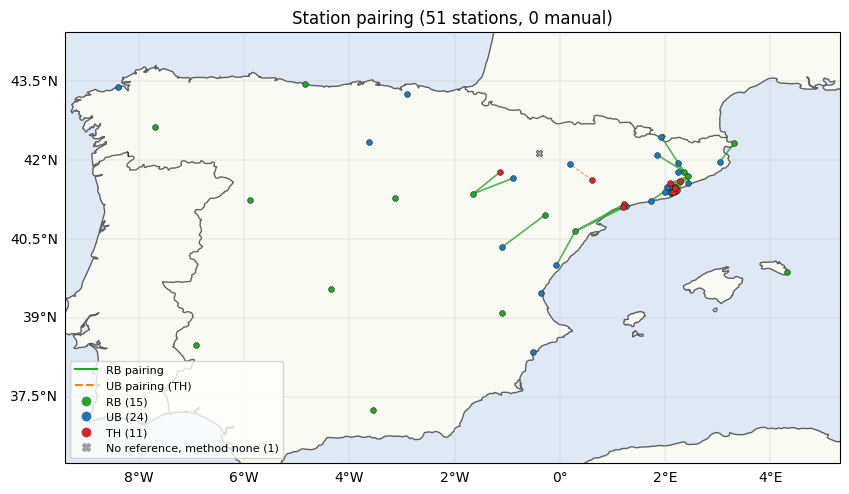

In [31]:
###################Edit here#########################
pairing_countries = Countries      # e.g. ['ES']
pairing_classes   = ['RB', 'UB', 'TH']
###################Stop here#########################
fig, ax = pv.plot_station_pairing_static(pairing_session.table, pairing_countries, pairing_classes)
plt.show()

#### **4.6.3 Edit the pairing as CSV**

1. Run the first cell below. It writes the current pairing to `station_pairing_user.csv` in the output folder and, in Colab, downloads it.
2. Open the file (e.g. in Excel) and change only `paired_rb_id`, `paired_ub_id`, `method` (`option1`, `option2`, `option2_ub_paired`, `none`, or empty to derive it from the pairing) or `comment`. Other columns are recomputed.
3. Upload it with the second cell (`UPLOAD_PAIRING_CSV = True` in Colab) or save it back as `station_pairing_user.csv` in the output folder, then run the second cell.

On loading, every id must exist, a paired RB must be an RB station and a paired UB a UB station; otherwise the file is rejected with a list of errors. Pairs beyond the distance or altitude limits only give a warning. Changed stations are marked `source = manual` and the changes against the default pairing are listed. The map above is redrawn. Set `USE_USER_PAIRING = True` to start from this file in later sessions.

In [32]:
pairing_session.export_csv(pairing_user_path)
print(f'Pairing table ({len(pairing_session.table)} stations) written to {pairing_user_path}')
pv.download_file(pairing_user_path)

Pairing table (51 stations) written to /content/drive/MyDrive/CAMS_Tool_output/station_pairing_user.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
# Set True in Colab to choose the edited CSV on your computer; otherwise place it in the output folder.
UPLOAD_PAIRING_CSV = False

if UPLOAD_PAIRING_CSV:
    pv.upload_pairing_csv(pairing_user_path)

if os.path.exists(pairing_user_path):
    try:
        pairing_report = pairing_session.load_csv(pairing_user_path)
        print(pairing_report.summary())
        display(pairing_report.changes)
        display(pr.method_counts(pairing_session.table))
    except pr.PairingValidationError as exc:
        print(exc)
        print('The pairing was not changed. Fix the CSV and run this cell again.')
else:
    print(f'No edited pairing found at {pairing_user_path}.')

0 station(s) differ from the default pairing.


,station_id,field,default_value,new_value


method,none,option1,option2,option2_ub_paired
class,,,,
RB,0,15,0,0
TH,1,10,0,1
UB,0,18,6,0


<a name="5"></a>
## **5- Flag dust days with CAMS data**

Two flags are assigned to every station and day:

*   Dust day (`dust_flag`, stored as `cams_dust_flag` in section 6): the CAMS dust concentration at the station is above `CAMS_dust_threshold` (default 5 µg/m³). These are the natural-event days.
*   Exceedance (`Exceedance`): the measured daily mean is above the daily limit value, `POLLUTANT_daily_threshold` (default: 45 µg/m³ for $PM_{10}$ or 25 µg/m³ for $PM_{2.5}$).

The natural contribution is quantified and subtracted on **every** dust day in Section 6, whether or not there is an exceedance.

In [34]:
if not(LOAD_PARQUET_DATA):
  # Flag dust days for cams dust > threshold selected
  df['dust_flag'] = df['cams_dust'] > CAMS_dust_threshold
  df['Exceedance'] = df['daily_mean'] > POLLUTANT_daily_threshold

  print('Below shows the new table with dust flag and Exceedance')
  display(df.head())

  # Inspect the rows with negative values to see which stations/dates are problematic
  negative_rows = df[df['daily_mean'] < 0]
  print(f"Number of rows with negative daily_mean: {len(negative_rows)}")
  if not negative_rows.empty:
      display(negative_rows.sort_values('daily_mean').head(10))
  else:
      print("No negative values found in the current 'df' variable.")

<a name="6"></a>
## **6 - Calculate the dust contribution**

The natural contribution is quantified with the method set in the pairing table (section 4.6). Event days (CAMS dust days) are excluded from every reference window.

**Option 1 – regional background (preferred).** At the paired RB station, for each event day *d*, the reference is the `REFERENCE_PERCENTILE` (50th) percentile of the days *d*−15 … *d*+15 that are not event days. The net natural load at the RB is max(measured RB(*d*) − reference, 0). The same daily load is subtracted at every station paired to that RB, including the RB itself.

**Option 2 – self-calibration (UB without suitable RB).** At the station itself, window *d*−3 … *d*+3 without event days. For a multi-day episode, the 3 days before its start and the 3 days after its end (without event days) are the reference for every day of the episode.

**TH stations** do not self-calibrate: they use the Option 1 load of their RB or, without a suitable RB, the Option 2 load of their paired UB.

If fewer than `MIN_REFERENCE_DAYS_OPTION1` / `MIN_REFERENCE_DAYS_OPTION2` valid reference days are available, the day is flagged `insufficient_reference` and nothing is subtracted.

The contribution is subtracted on every event day, with or without an exceedance; other days get 0. Adjusted value = measured − contribution (never below 0). A dust day is confirmed only when the quantified contribution is > 0.

The calculation uses the whole downloaded period (from 14 December of the previous year) and then keeps the selected year.

In [35]:
import gc

if not(LOAD_PARQUET_DATA):
  df_target_year = nc.run_natural_deduction(
      df,
      pairing_session.table,
      YEAR,
      pollutant=POLLUTANT,
      dust_threshold=CAMS_dust_threshold,
      params=METHOD_PARAMS,
      limits=LIMITS,
  )
  gc.collect()
  display(df_target_year[nc.NEW_COLUMNS].head())

New columns in the daily table: `station_class`, `method`, `reference_station_id`, `reference_value` (percentile reference at the reference station), `natural_contribution`, `cams_dust_flag`, `confirmed_dust_day`, `adjusted_value`, `insufficient_reference` and `pairing_source`. The previous column names are kept for the plots: `dust_flag` = `cams_dust_flag`, `pollutant_median` = `reference_value`, `Dust_contribution` = `natural_contribution`, `corrected_pollutant` = `adjusted_value`.

The cell below summarises the event days per class and method.

In [36]:
if not(LOAD_PARQUET_DATA):
  event_days = df_target_year[df_target_year['cams_dust_flag']]
  display(
      event_days.groupby(['station_class', 'method'], observed=True)
      .agg(
          stations=('Samplingpoint', 'nunique'),
          cams_dust_days=('cams_dust_flag', 'sum'),
          confirmed_dust_days=('confirmed_dust_day', 'sum'),
          insufficient_reference=('insufficient_reference', 'sum'),
          mean_contribution=('natural_contribution', 'mean'),
      )
  )

Alternative methods of using cams dust only

Corrected Dust = $(1+ \frac{Observed PM_{10}-Renalaysis PM_{10}}{Reanalysis PM_{10}})\ x\ Reanalysis Dust$


In [ ]:
# obs_2024 = df[(df['day'] >= '2024-01-01') & (df['day'] < '2025-01-01')].copy()
# # Ratio of (Observed Mean / CAMS Modeled PM10) * CAMS Dust
# calculation = (obs_2024['daily_mean'] / obs_2024['cams_pm10']) * obs_2024['cams_dust']

# # Apply only where dust_flag is True, otherwise keep original daily_mean (or NaN)
# obs_2024['dust'] = np.where(
#     (obs_2024['dust_flag'] == True) & (obs_2024['Exceedance'] == True),
#     calculation,
#     obs_2024['daily_mean'] # Or np.nan if you only want dust values
# )
# obs_2024['corrected_PM10'] = obs_2024['daily_mean'].astype(float)
# mask = obs_2024['dust_flag'] & obs_2024['Exceedance']
# obs_2024.loc[mask, 'corrected_PM10'] = obs_2024.loc[mask, 'daily_mean'] - obs_2024.loc[mask, 'dust']

### **6.1 Check unconfirmed dust days and insufficient references**

When the measurement at the reference station is not above its reference, the net load is 0 and the CAMS dust day is not confirmed (`confirmed_dust_day = False`). This can happen because CAMS flags dust that does not reach the ground, or because strong winds during a dust event lower local PM. Days without enough valid reference days are flagged `insufficient_reference` and keep the measured value.

In [37]:
if not(LOAD_PARQUET_DATA):
  cams_days = int(df_target_year['cams_dust_flag'].sum())
  confirmed = int(df_target_year['confirmed_dust_day'].sum())
  insufficient = int(df_target_year['insufficient_reference'].sum())
  print(f'CAMS dust days: {cams_days}, confirmed: {confirmed}, '
        f'not confirmed: {cams_days - confirmed - insufficient}, insufficient reference: {insufficient}')
  print(f"Negative contributions: {int((df_target_year['natural_contribution'] < 0).sum())}")

<a name="7"></a>
## **7 - Save or load results**



*   First run (`LOAD_PARQUET_DATA` = False): the daily results for all stations are saved as a Parquet file named after the selected settings (e.g. CAMS_dust_PM10_deduction_E2a_hour_2025_MA6.parquet) in the output folder.
*   Later runs (`LOAD_PARQUET_DATA` = True): Sections 3 to 6 are skipped and the saved file is loaded directly, without downloading or processing the data again. With `REAPPLY_PAIRING_ON_LOAD = True` the deduction is recomputed on the loaded table with the current pairing (section 4.6), so pairing edits are used without reprocessing CAMS. The saved file only covers the selected year, so the first and last days of the year then have a shorter reference window.

From here on, the notebook works the same way whether the results were just computed or loaded from file.

In [38]:
import pyarrow as pa
import pyarrow.parquet as pq

# deduction_parquet is set in section 4.6.
if not LOAD_PARQUET_DATA:
    table = pa.Table.from_pandas(df_target_year)
    pqwriter = pq.ParquetWriter(deduction_parquet, table.schema, use_dictionary=True, compression='snappy')
    pqwriter.write_table(table)
    pqwriter.close()
    print(f'save to {deduction_parquet}')
else:
    print(f'open {deduction_parquet}')
    df_target_year = pd.read_parquet(deduction_parquet)
    if REAPPLY_PAIRING_ON_LOAD:
        df_target_year = nc.compute_natural_contribution(
            df_target_year,
            pairing_session.table,
            dust_threshold=CAMS_dust_threshold,
            params=METHOD_PARAMS,
            daily_limit=POLLUTANT_daily_threshold,
        )
        print('Deduction recomputed with the current pairing.')

open /content/drive/MyDrive/CAMS_Tool_output/CAMS_dust_PM2.5_deduction_E1a_day_2025_MA6.parquet


/content/natural_contribution.py:171: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return index, frame["v"].to_numpy(dtype=float), frame["e"].fillna(False).to_numpy(dtype=bool)
/content/natural_contribution.py:171: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return index, frame["v"].to_numpy(dtype=float), frame["e"].fillna(False).to_numpy(dtype=bool)
/content/natural_contribution.py:171: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) ins

Deduction recomputed with the current pairing.


### **7.1 Station summary**

The adjusted daily series is summarised per station for the selected year. Exceedances and annual means are recalculated from the daily values with and without the natural contribution, so the adjusted annual mean includes the subtraction on every dust day.

<center>

| Column | Description |
|:---|:---|
| **station_class**, **method**, **reference_station_id**, **pairing_source** | Class, method and reference station used, and whether the pairing is default or manual |
| **cams_dust_days**, **confirmed_dust_days**, **insufficient_reference_days** | CAMS dust days, dust days with a contribution > 0, and days without enough reference data |
| **exceedances_measured** / **exceedances_adjusted** | Days above the daily limit before / after subtracting the natural contribution |
| **exceedances_natural** | Exceedances attributed to natural sources |
| **annual_mean_measured** / **annual_mean_adjusted** | Annual mean before / after subtraction |
| **annual_limit_exceeded_measured** / **_adjusted** | Annual mean above the annual limit value |

</center>

The previous columns (`Exceedance_days`, `Dust_exceedance_days`, `NonDust_exceedance`, `Average_pollutant`, `Average_pollutant_dust_removed`) are kept with the same meaning for the maps in section 8.

In [39]:
if 'adjusted_value' in df_target_year.columns:
    station_table = nc.station_indicators(
        df_target_year,
        daily_limit=POLLUTANT_daily_threshold,
        annual_limit=POLLUTANT_annual_threshold,
    )
else:
    # Parquet from an earlier version, loaded with REAPPLY_PAIRING_ON_LOAD = False.
    station_table = cams_daily.station_summary_table(df_target_year, POLLUTANT_daily_threshold)
display(station_table.head())

,Samplingpoint,Latitude,Longitude,Altitude,station_class,method,reference_station_id,pairing_source,n_days,cams_dust_days,...,exceedances_natural,annual_mean_measured,annual_mean_adjusted,annual_limit_exceeded_measured,annual_limit_exceeded_adjusted,Exceedance_days,Dust_exceedance_days,NonDust_exceedance,Average_pollutant,Average_pollutant_dust_removed
0,ES/SP_03014008_9_M,38.34028,-0.50667,55.0,UB,option2,ES/SP_03014008_9_M,default,350,40,...,5,11.387143,10.599286,True,True,12,5,7,11.387143,10.599286
1,ES/SP_06016999_9_M,38.47278,-6.92333,377.0,RB,option1,ES/SP_06016999_9_M,default,350,46,...,5,8.200886,7.203584,False,False,9,5,4,8.200886,7.203584
2,ES/SP_07032999_9_M,39.87611,4.32389,78.0,RB,option1,ES/SP_07032999_9_M,default,342,30,...,0,3.963914,3.704630,False,False,0,0,0,3.963914,3.704630
3,ES/SP_08014002_9_M,41.77110,2.25070,427.0,UB,option1,ES/SP_08137001_9_46,default,314,26,...,0,10.012739,9.604659,True,False,6,0,6,10.012739,9.604659
4,ES/SP_08019004_9_M,41.40390,2.20450,3.0,UB,option1,ES/SP_08259002_9_M,default,344,30,...,1,12.192151,11.863663,True,True,3,1,2,12.192151,11.863663



## **7.2 Export to csv**

The station summary is saved as a CSV file in the output folder, e.g. ES_station_annual_PM10_E2a_hour_2025_MA6.csv.

In [40]:
# If you would like to save this file please uncomment the line below
if len(Countries) >= 2:
    key = 'muti_countries'
else:
    key = Countries[0]

# Determine the output path for CSV files
if USE_GOOGLE_DRIVE:
    csv_output_dir = gdrive_output_dir
else:
    csv_output_dir = project_dir

station_table.to_csv(os.path.join(csv_output_dir, f'{key}_station_annual_{POLLUTANT}_{dataset}_{EEA_temporal_flag}_{YEAR}_MA{Basline_MA_days}.csv'))

### **7.2.1 Optional: model-specific dust threshold**

`CAMS_dust_threshold` stays a parameter. The cell below recomputes the deduction for a list of thresholds and, per country (or region), reports the share of CAMS dust days on which the quantified contribution is > 0. The suggested threshold is the lowest one from which every higher threshold has at least `SWEEP_MIN_SHARE` confirmed dust days. Each threshold is a full recomputation, so this can take several minutes for many countries.

In [41]:
###################Edit here#########################
RUN_THRESHOLD_SWEEP = False
SWEEP_THRESHOLDS    = [2, 3, 4, 5, 6, 7, 8, 10]   # µg/m3
SWEEP_GROUP         = 'country'                   # or a region column present in the table
SWEEP_MIN_SHARE     = 0.9                         # share of CAMS dust days with contribution > 0
SWEEP_MIN_DAYS      = 10                          # ignore thresholds with fewer CAMS dust days
###################Stop here#########################

if RUN_THRESHOLD_SWEEP:
    import dust_threshold_sensitivity as sens
    sweep_input = df if not LOAD_PARQUET_DATA else df_target_year
    parts = []
    for threshold in SWEEP_THRESHOLDS:
        frame = nc.compute_natural_contribution(
            sweep_input, pairing_session.table, dust_threshold=threshold,
            params=METHOD_PARAMS, daily_limit=POLLUTANT_daily_threshold,
        )
        parts.append(sens.contribution_consistency({float(threshold): frame}, group_col=SWEEP_GROUP))
        del frame
        gc.collect()
    threshold_consistency = pd.concat(parts, ignore_index=True)
    display(threshold_consistency)
    display(sens.lowest_consistent_threshold(
        threshold_consistency, group_col=SWEEP_GROUP,
        min_share=SWEEP_MIN_SHARE, min_days=SWEEP_MIN_DAYS,
    ))

### **7.3 Optional: plot hourly and daily results together**

Set `COMBINE_HOURLY_DAILY_FOR_VIZ = True` in the next cell to stack the saved hourly and daily deduction Parquet files into one table for the plots in Section 8. Leave it `False` to keep the plots on the single resolution chosen in Section 2.

Both files have to exist already:

`CAMS_dust_{POLLUTANT}_deduction_{dataset}_hour_{YEAR}_MA{Basline_MA_days}.parquet`

`CAMS_dust_{POLLUTANT}_deduction_{dataset}_day_{YEAR}_MA{Basline_MA_days}.parquet`

The station summary CSV from Section 7.2 is written before this step and stays the single-resolution table. Turning the option on replaces `df_target_year` and `station_table` for the plots. Run Section 7.1 again if you need that single-resolution summary back in memory.

**Time-zone disclaimer.** Do not read a shared date as the same 24 hours.

* The hourly file treats EEA hourly stamps as fixed UTC+1 (no daylight-saving time), converts them to UTC, and stores `day` as that UTC day. CAMS dust on those rows is the mean of the UTC day.
* The daily file keeps EEA `Start` in the station's own local time, taken from the `Timezone` label in `DataExtract.csv` (`UTC`, `UTC+01`, `UTC-04`, and so on). `day` is that local calendar date. CAMS dust on those rows is the mean of the UTC hours inside `[day 00:00 − offset, next day 00:00 − offset)`.

A label such as 2024-06-15 in the hourly file is the UTC day. The same label in the daily file is local midnight to the next local midnight. At a station that is not on UTC, those windows are shifted by the station's time zone. The merged table stacks the two products. It does not join them onto one physical day. `Samplingpoint` is labelled with the clock so maps and time series draw the two products as separate stations.


In [42]:
# Set True to plot the hourly and the daily deduction tables together.
# Both Parquet files must already exist. Read the time-zone disclaimer above before turning this on.
COMBINE_HOURLY_DAILY_FOR_VIZ = True

if COMBINE_HOURLY_DAILY_FOR_VIZ:
    def _deduction_parquet(temporal_flag):
        return cams_daily.deduction_parquet_path(
            OUTPUT_DIR, POLLUTANT, dataset, temporal_flag, YEAR, Basline_MA_days
        )

    df_target_year = cams_daily.load_and_combine_deduction_parquets(
        _deduction_parquet('hour'),
        _deduction_parquet('day'),
    )
    station_table = cams_daily.station_summary_table(
        df_target_year,
        POLLUTANT_daily_threshold,
    )
    print(
        'Section 8 will plot both products. Samplingpoint labels include the clock '
        '(UTC day or station local day) so the two series stay separate.'
    )
    display(df_target_year.groupby(['eea_resolution', 'day_definition'], observed=False).size())
    display(station_table.head())
else:
    print(
        f'Section 8 keeps the single product for EEA_temporal_flag={EEA_temporal_flag!r}.'
    )

Combined 60,569 hourly rows and 16,661 daily rows into 77,230 rows. The hourly `day` is a UTC day; the daily `day` is the station local day.
Section 8 will plot both products. Samplingpoint labels include the clock (UTC day or station local day) so the two series stay separate.


,,0
eea_resolution,day_definition,
day,station local day,16661
hour,UTC day,60569


,Samplingpoint,eea_resolution,day_definition,Latitude,Longitude,Altitude,Exceedance_days,Dust_exceedance_days,NonDust_exceedance,Average_pollutant,Average_pollutant_dust_removed
0,ES/SP_01036004_9_46 (UTC day),hour,UTC day,43.14407,-2.96337,122.0,3,3,0,8.362450,7.751455
1,ES/SP_01055001_9_49 (UTC day),hour,UTC day,42.87520,-3.23170,911.0,2,2,0,4.719561,4.238360
2,ES/SP_01059009_9_49 (UTC day),hour,UTC day,42.85607,-2.66779,518.0,6,6,0,9.867857,9.206452
3,ES/SP_01059012_9_49 (UTC day),hour,UTC day,42.84361,-2.66139,50.0,2,1,1,9.468913,8.948895
4,ES/SP_02003002_9_49 (UTC day),hour,UTC day,38.98080,-1.84520,691.0,3,2,1,8.252076,7.183248


<a name="8"></a>
## **8 - Visualization**

The results can be shown as interactive or static plots. If `COMBINE_HOURLY_DAILY_FOR_VIZ` is True in the cell above, these plots use the stacked hourly and daily tables. Otherwise they use the single resolution from Section 7. If interactive widgets (e.g. ipywidgets) do not work in your environment, skip to the static plots further below.




### **8.1 Map - Corrected annual mean and exceedance days**

This interactive map shows, for each station, the annual mean concentration after subtracting natural dust (colour) and the number of exceedance days not caused by dust (marker size). Move your cursor to the station location to see the results.

In [43]:

import plotly.express as px
import plotly.graph_objects as go


def plot_interactive_station_map(
    df,
    color_column,
    size_column=None,
    color_type='auto',             # 'auto', 'continuous_scale', 'discrete_sequence'
    colorscale='Viridis',
    zoom=5,
    center_lat=None,
    center_lon=None,
    map_title=None,
    map_subtitle=None,
    colorbar_title=' ',            # Default to single space to show no title if unwanted
    marker_size_range=[8, 20],     # [min_px, max_px] — px uses only size_max directly
    n_discrete_colors=10,
    size_legend_min=None,
    size_legend_max=None,
    size_legend_steps=4,
    color_min=None,
    color_max=None,
):
    """
    Plots an interactive scatter map of stations using Plotly Express.

    Colab/OSM note: mapbox_style='open-street-map' hits tile.openstreetmap.org
    and 403s in Colab (missing Referer). This uses MapLibre scatter_map with
    Carto Voyager (OSM data + required OSM attribution).
    """
    use_maplibre = hasattr(px, 'scatter_map')
    scatter = px.scatter_map if use_maplibre else px.scatter_mapbox
    LegendTrace = go.Scattermap if use_maplibre else go.Scattermapbox
    trace_type = 'scattermap' if use_maplibre else 'scattermapbox'
    style_key = 'map_style' if use_maplibre else 'mapbox_style'
    # Colab-safe OSM-derived tiles. Do not use 'open-street-map' in Colab.
    style_value = 'carto-voyager' if use_maplibre else 'carto-positron'

    # Set default center for Europe if not provided
    default_center_lat = 50.0  # Approx. center of Europe
    default_center_lon = 10.0  # Approx. center of Europe

    if center_lat is None:
        center_lat = default_center_lat
    if center_lon is None:
        center_lon = default_center_lon

    center_dict = {'lat': center_lat, 'lon': center_lon}

    plotting_df = df.copy()
    color_col_to_plot = color_column

    plot_kwargs = {
        'lat': 'Latitude',
        'lon': 'Longitude',
        'size': size_column,
        'zoom': zoom,
        'center': center_dict,
        'hover_name': 'Samplingpoint',
        style_key: style_value,
        'size_max': marker_size_range[1],
    }

    is_color_numeric = pd.api.types.is_numeric_dtype(plotting_df[color_column])

    if color_type == 'continuous_scale' or (color_type == 'auto' and is_color_numeric):
        plot_kwargs['color'] = color_col_to_plot
        plot_kwargs['color_continuous_scale'] = colorscale
        if color_min is not None or color_max is not None:
            plot_kwargs['range_color'] = [
                color_min if color_min is not None else plotting_df[color_column].min(),
                color_max if color_max is not None else plotting_df[color_column].max(),
            ]

    elif color_type == 'discrete_sequence' or (color_type == 'auto' and not is_color_numeric):
        if is_color_numeric:
            color_col_to_plot = color_column + '_binned'
            plotting_df[color_col_to_plot] = pd.cut(
                plotting_df[color_column],
                bins=n_discrete_colors,
                labels=[f'{i}-{i+1}' for i in range(n_discrete_colors)],
                include_lowest=True,
            )
        plot_kwargs['color'] = color_col_to_plot
        plot_kwargs['color_discrete_sequence'] = colorscale if isinstance(colorscale, list) else px.colors.qualitative.Plotly

    fig = scatter(plotting_df, **plot_kwargs)

    if colorbar_title and (color_type == 'continuous_scale' or (color_type == 'auto' and is_color_numeric)):
        fig.update_coloraxes(colorbar=dict(title=colorbar_title, tickformat=".2f"))

    custom_cols, custom_idx = [], {}
    pos = 0
    if size_column is not None:
        custom_cols.append(size_column); custom_idx['size'] = pos; pos += 1
    if color_column and is_color_numeric:
        custom_cols.append(color_column); custom_idx['color'] = pos; pos += 1

    if custom_cols:
        fig.update_traces(
            customdata=plotting_df[custom_cols].to_numpy(),
            selector=dict(type=trace_type),
        )
        hover_lines = ["<b>%{hovertext}</b>"]
        if 'size' in custom_idx:
            hover_lines.append(f"{size_column}: %{{customdata[{custom_idx['size']}]:.0f}}")
        if 'color' in custom_idx:
            hover_lines.append(f"{color_column}: %{{customdata[{custom_idx['color']}]:.2f}}")
        hover_lines.append("<extra></extra>")
        fig.update_traces(
            hovertemplate="<br>".join(hover_lines),
            selector=dict(type=trace_type),
        )

    fig.update_layout(
        title_text=map_title,
        title_x=0.5,
        title_y=0.95,
    )
    if map_subtitle:
        fig.add_annotation(
            text=map_subtitle,
            xref="paper", yref="paper",
            x=0.5, y=0.91,
            showarrow=False,
            font=dict(size=12, color="gray"),
            xanchor="center", yanchor="top",
        )

    # fig.add_annotation(
    #     text="© OpenStreetMap contributors © CARTO",
    #     xref="paper", yref="paper",
    #     x=0.99, y=0.01,
    #     showarrow=False,
    #     font=dict(size=10, color="#444444"),
    #     xanchor="right", yanchor="bottom",
    #     bgcolor="rgba(255,255,255,0.7)",
    #     borderpad=4,
    # )

    if size_column is not None:
        data_min = float(np.nanmin(plotting_df[size_column]))
        data_max = float(np.nanmax(plotting_df[size_column]))

        smin = data_min if size_legend_min is None else float(size_legend_min)
        smax = data_max if size_legend_max is None else float(size_legend_max)
        if smax < smin:
            smin, smax = smax, smin

        size_values = [smin] if np.isclose(smin, smax) else list(np.linspace(smin, smax, max(2, size_legend_steps)))

        main_trace = next((t for t in fig.data if t.type == trace_type), None)
        if main_trace and hasattr(main_trace, "marker") and hasattr(main_trace.marker, "sizeref"):
            computed_sizeref = main_trace.marker.sizeref
            sizemode = getattr(main_trace.marker, "sizemode", "diameter")
            sizemin = getattr(main_trace.marker, "sizemin", None)
        else:
            computed_sizeref = None
            sizemode = "diameter"
            sizemin = None

        if center_dict is not None:
            lat0, lon0 = center_dict["lat"], center_dict["lon"]
        else:
            lat0 = float(plotting_df['Latitude'].iloc[0])
            lon0 = float(plotting_df['Longitude'].iloc[0])

        for v in size_values:
            fig.add_trace(LegendTrace(
                lat=[lat0], lon=[lon0],
                mode="markers",
                marker=dict(
                    size=v,
                    sizemode=sizemode,
                    sizeref=computed_sizeref,
                    sizemin=sizemin,
                    color="blue",
                ),
                name=f"{v:.2f}",
                legendgroup="size-legend",
                showlegend=True,
                visible="legendonly",
                hoverinfo="skip",
            ))

        fig.update_layout(
            legend=dict(
                title=f"{size_column}",
                itemsizing="trace",
                yanchor="bottom",
                y=0.01,
                xanchor="left",
                x=0.01,
                bgcolor="rgba(255,255,255,0.6)",
            )
        )
        fig.update_traces(legendrank=100, selector=dict(legendgroup="size-legend"))

    return fig


fig = plot_interactive_station_map(
    df=station_table,
    color_column='Average_pollutant_dust_removed',
    size_column='NonDust_exceedance',
    color_type='continuous_scale',
    colorscale='viridis',
    zoom=3,
    map_title=f'Corrected {POLLUTANT} concentration (colorbar) and corrected nr. of exceedance days (size of dots)',
    colorbar_title='µg/m³',
    size_legend_min=1,
    size_legend_max=19,
    size_legend_steps=3,
    marker_size_range=[20, 40],
    color_min=0,
    color_max=50,
)
fig.show(renderer='colab' if IN_COLAB else None)




### **8.2 Station time series**

Click a station on the interactive map below to plot its time series of measured and corrected concentrations. The colour and size of each marker show the measured annual mean concentration, before the natural dust contribution is subtracted.


In [44]:
"""Clickable CAMS dust map using the same Plotly style as the annual map.

Paste this cell after df_target_year and the year/threshold settings exist.
If needed in Colab, first run: %pip install "plotly>=6" anywidget ipywidgets
"""

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import display
from ipywidgets import HTML, Output, VBox
import plotly.express as px
import plotly.graph_objects as go
from ipywidgets import Dropdown


class MapFigureWidget(go.FigureWidget):
    """Keep the map responsive when Plotly sends internal viewport data.

    Plotly may send a ``map._derived`` update when the user zooms or moves
    the map. It describes the viewport but is not a writable layout setting.
    The widget ignores that update and still processes ordinary map changes.
    """

    def _perform_plotly_relayout(self, relayout_data):
        if isinstance(relayout_data, dict):
            relayout_data = {
                key: value for key, value in relayout_data.items()
                if not (key.split(".", 1)[0].startswith("map")
                        and key.endswith("._derived"))
            }
        return super()._perform_plotly_relayout(relayout_data)


def plot_station_timeseries(
    station_name,
    obs_df,
    station_column="Samplingpoint",
    time_column="day",
    observed_pollutant_col="daily_mean",
    corrected_pollutant_col="corrected_pollutant",
    cams_dust_col="cams_dust",
    dust_flag_col="dust_flag",
    altitude_col="Altitude",
    exceedance_threshold=50.0,
    cams_dust_threshold=5.0,
    pollutant="PM10",
    year=2025,
    figsize=(12, 5),
):
    """Plot observed and dust-corrected PM alongside CAMS dust at one station.

    The upper panel compares the measured daily PM concentration with the
    concentration after the estimated natural dust contribution is removed.
    Red points identify days flagged as dusty. The lower panel shows CAMS
    modeled dust, which the notebook uses to identify those days.

    Parameters
    ----------
    station_name : str
        Unique identifier of the station to plot.
    obs_df : pandas.DataFrame
        Daily station observations and dust-correction results.
    station_column : str, default "Samplingpoint"
        Column containing station identifiers.
    time_column : str, default "day"
        Column containing observation dates. Dates are interpreted in UTC.
    observed_pollutant_col : str, default "daily_mean"
        Column containing the measured daily PM concentration in µg/m³.
    corrected_pollutant_col : str, default "corrected_pollutant"
        Column containing daily PM after estimated natural dust subtraction.
    cams_dust_col : str, default "cams_dust"
        Column containing the CAMS modeled dust concentration in µg/m³.
    dust_flag_col : str, default "dust_flag"
        Boolean column marking days identified as dusty. Optional for plotting.
    altitude_col : str, default "Altitude"
        Station altitude column, shown in the title when available.
    exceedance_threshold : float, default 50.0
        Daily PM threshold drawn as a line in the upper panel, in µg/m³.
    cams_dust_threshold : float, default 5.0
        CAMS dust threshold drawn in the lower panel, in µg/m³.
    pollutant : str, default "PM10"
        Pollutant name used in the title, axis labels, and legend.
    year : int, default 2025
        Calendar year displayed. Rows from other years are omitted.
    figsize : tuple, default (12, 5)
        Width and height of the Matplotlib figure, in inches.

    Returns
    -------
    fig : matplotlib.figure.Figure
        The two-panel time-series figure.
    axes : numpy.ndarray
        The upper PM axis and lower CAMS dust axis.
    """
    # Step 1: Check that the columns needed for both panels are present.
    required = [station_column, time_column, observed_pollutant_col,
                corrected_pollutant_col, cams_dust_col]
    missing = [col for col in required if col not in obs_df.columns]
    if missing:
        raise ValueError(f"Missing columns for the time series: {missing}")

    # Step 2: Keep only the selected station; leave the original table intact.
    station_data = obs_df.loc[obs_df[station_column] == station_name].copy()
    if station_data.empty:
        raise ValueError(f"Station {station_name!r} is not in the observations.")

    # Step 3: Make dates comparable, select the requested UTC year, and sort.
    # A date without timezone information is interpreted as UTC here.
    station_data[time_column] = pd.to_datetime(
        station_data[time_column], errors="coerce", utc=True
    )
    year_start = pd.Timestamp(f"{year}-01-01", tz="UTC")
    next_year = pd.Timestamp(f"{year + 1}-01-01", tz="UTC")
    station_data = station_data.loc[
        (station_data[time_column] >= year_start)
        & (station_data[time_column] < next_year)
    ].sort_values(time_column)
    if station_data.empty:
        raise ValueError(f"Station {station_name!r} has no data for {year}.")

    # Step 4: Add the station altitude to the title when metadata is available.
    altitude = None
    if altitude_col in station_data.columns:
        known_altitudes = pd.to_numeric(
            station_data[altitude_col], errors="coerce"
        ).dropna()
        if not known_altitudes.empty:
            altitude = float(known_altitudes.iloc[0])

    # Step 5: Top panel: observed and corrected PM, dust days, PM threshold.
    fig, axes = plt.subplots(
        2, 1, figsize=figsize, height_ratios=(3, 1), sharex=True
    )
    axes[0].plot(
        station_data[time_column], station_data[observed_pollutant_col],
        label=f"Observed {pollutant}", linewidth=1.2,
    )
    axes[0].plot(
        station_data[time_column], station_data[corrected_pollutant_col],
        label=f"Corrected {pollutant}", linewidth=1.2, linestyle="--",
    )
    if dust_flag_col in station_data.columns:
        dust_days = station_data.loc[
            station_data[dust_flag_col].fillna(False).astype(bool)
        ]
        if not dust_days.empty:
            axes[0].scatter(
                dust_days[time_column], dust_days[observed_pollutant_col],
                color="crimson", s=20, label="Flagged dust day", zorder=3,
            )
    axes[0].axhline(
        exceedance_threshold, color="royalblue", linestyle=":",
        label=f"Daily threshold ({exceedance_threshold:g} µg/m³)",
    )
    alt_label = f" | altitude {altitude:.0f} m" if altitude is not None else ""
    axes[0].set_title(f"{station_name} | {pollutant} | {year}{alt_label}")
    axes[0].set_ylabel(f"{pollutant} (µg/m³)")
    axes[0].grid(alpha=0.25)
    axes[0].legend(loc="upper right", fontsize=8)

    # Step 6: Bottom panel: CAMS dust and the dust-day flagging threshold.
    axes[1].plot(
        station_data[time_column], station_data[cams_dust_col],
        color="forestgreen", linewidth=1.3, label="CAMS dust",
    )
    axes[1].axhline(
        cams_dust_threshold, color="forestgreen", linestyle=":",
        label=f"Dust flag threshold ({cams_dust_threshold:g} µg/m³)",
    )
    axes[1].set_ylabel("CAMS dust (µg/m³)")
    axes[1].set_xlabel("Date (UTC)")
    axes[1].set_xlim(year_start, next_year)
    axes[1].grid(alpha=0.25)
    axes[1].legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    return fig, axes


def map_timeseries_clickable_plot(
    obs_df,
    year,
    exceedance_threshold,
    cams_dust_threshold,
    pollutant,
    station_col="Samplingpoint",
    time_col="day",
    observed_pollutant_col="daily_mean",
    corrected_pollutant_col="corrected_pollutant",
    cams_dust_col="cams_dust",
    dust_flag_col="dust_flag",
    altitude_col="Altitude",
    lat_col="Latitude",
    lon_col="Longitude",
    value_col="daily_mean",
    cmap_name="plasma",
    radius_range=(6, 16),
    vmin=None,
    vmax=None,
    legend_title=None,
    legend_bins=5,
    legend_round=1,
    legend_position="bottomright",  # kept for compatibility with the old call
    zoom=None,
):
    """Map stations and display a daily time series when one is selected.

    Each marker represents one station. Its color and size are based on the
    station's mean measured PM concentration over the selected year. Clicking
    a marker or selecting its identifier in the dropdown displays the observed
    PM, corrected PM, and CAMS dust time series underneath the map.

    Parameters
    ----------
    obs_df : pandas.DataFrame
        Daily station data, including measurements, correction, dust flags,
        and coordinates. Typically ``df_target_year`` from the notebook.
    year : int
        Calendar year included in the map and station time series.
    exceedance_threshold : float
        Daily PM threshold used for the upper time-series reference line.
    cams_dust_threshold : float
        CAMS dust threshold used for the lower time-series reference line.
    pollutant : str
        Pollutant name shown in titles and units, such as "PM10" or "PM2.5".
    station_col : str, default "Samplingpoint"
        Column containing the station identifier.
    time_col : str, default "day"
        Column containing daily dates, interpreted in UTC.
    observed_pollutant_col : str, default "daily_mean"
        Column with observed daily PM concentrations in µg/m³.
    corrected_pollutant_col : str, default "corrected_pollutant"
        Column with PM concentrations after estimated dust subtraction.
    cams_dust_col : str, default "cams_dust"
        Column with CAMS dust concentrations in µg/m³.
    dust_flag_col : str, default "dust_flag"
        Column marking days identified as dusty on the time series.
    altitude_col : str, default "Altitude"
        Optional station altitude metadata shown in the time-series title.
    lat_col, lon_col : str, defaults "Latitude", "Longitude"
        Columns with station coordinates in decimal degrees.
    value_col : str, default "daily_mean"
        Daily concentration column averaged by station to set marker color
        and marker size. It normally represents observed PM.
    cmap_name : str, default "plasma"
        Plotly color scale for the marker averages.
    radius_range : tuple, default (6, 16)
        Minimum and maximum marker sizes in pixels.
    vmin, vmax : float or None, defaults None
        Optional lower and upper limits for marker color and size scaling.
        When omitted, limits come from the station averages.
    legend_title : str or None, default None
        Title of the concentration color bar.
    legend_bins : int, default 5
        Number of labeled values along the color bar (minimum: two).
    legend_round : int, default 1
        Decimal places shown on the color bar.
    legend_position : str, default "bottomright"
        Retained for compatibility with the old function; unused by Plotly.
    zoom : float or None, default None
        Initial map zoom. If omitted, the function chooses a zoom level
        based on the geographic spread of stations.

    Returns
    -------
    ipywidgets.VBox
        Map widget, station dropdown, and time-series output area.
    """
    # Step 1: Validate input and keep only observations from the chosen year
    # with a station ID, usable coordinates, and a measured value.
    needed = [station_col, time_col, lat_col, lon_col, value_col,
              observed_pollutant_col, corrected_pollutant_col, cams_dust_col]
    missing = [column for column in needed if column not in obs_df.columns]
    if missing:
        raise ValueError(f"Missing columns for the interactive map: {missing}")

    df = obs_df.copy()
    df[time_col] = pd.to_datetime(df[time_col], utc=True, errors="coerce")
    start = pd.Timestamp(f"{year}-01-01", tz="UTC")
    end = pd.Timestamp(f"{year + 1}-01-01", tz="UTC")
    df = df.loc[(df[time_col] >= start) & (df[time_col] < end)].copy()
    for column in (lat_col, lon_col, value_col):
        df[column] = pd.to_numeric(df[column], errors="coerce")
    df = df.dropna(subset=[station_col, lat_col, lon_col, value_col])
    if df.empty:
        return VBox([HTML(f"No stations with coordinates and values for {year}.")])

    # Step 2: Replace daily rows with one marker per station. Use the mean of
    # value_col for marker color and size, and its first coordinate pair.
    summary = (
        df.groupby(station_col, observed=True, sort=False)
        .agg(average=(value_col, "mean"), latitude=(lat_col, "first"),
             longitude=(lon_col, "first"))
        .reset_index()
    )
    # Step 3: Set the map's color/size range and choose a suitable initial view.
    low = float(summary["average"].min()) if vmin is None else float(vmin)
    high = float(summary["average"].max()) if vmax is None else float(vmax)
    if high <= low:
        high = low + 1
    rmin, rmax = radius_range
    if rmin <= 0 or rmax < rmin:
        raise ValueError("radius_range must have increasing positive values")

    lat_span = summary["latitude"].max() - summary["latitude"].min()
    lon_span = summary["longitude"].max() - summary["longitude"].min()
    if zoom is None:
        zoom = 4 if lat_span > 12 or lon_span > 15 else 6
    center = {"lat": float(summary["latitude"].median()),
              "lon": float(summary["longitude"].median())}

    # Step 4: Build the station markers and their hover labels. Explicit pixel
    # sizes keep low-concentration stations visible in the widget renderer.
    size_fraction = np.clip(
        (summary["average"].to_numpy(dtype=float) - low) / (high - low), 0, 1
    )
    pixel_sizes = (rmin + (rmax - rmin) * size_fraction).tolist()
    station_trace = go.Scattermap(
        lat=summary["latitude"].to_numpy(dtype=float).tolist(),
        lon=summary["longitude"].to_numpy(dtype=float).tolist(),
        mode="markers",
        text=summary[station_col].astype(str).tolist(),
        customdata=summary[[station_col]].to_numpy(),
        hovertemplate=(
            "<b>%{text}</b><br>Average " + pollutant +
            ": %{marker.color:.2f} µg/m³<extra></extra>"
        ),
        marker={
            "symbol": "circle",
            "size": pixel_sizes,
            "sizemode": "diameter",
            "sizeref": 1,
            "color": summary["average"].to_numpy(dtype=float).tolist(),
            "colorscale": cmap_name,
            "cmin": low,
            "cmax": high,
            "opacity": 0.9,
            "showscale": True,
            "colorbar": {
                "title": legend_title or f"Average {pollutant} (µg/m³)",
                "tickvals": np.linspace(low, high, max(2, legend_bins)),
                "tickformat": f".{max(0, legend_round)}f",
            },
        },
    )
    fig = go.Figure(station_trace)
    fig.update_layout(
        map={"style": "carto-voyager", "center": center, "zoom": zoom},
        height=560,
        title=f"Observed {dataset} stations annual average {pollutant} ({year})",
        margin={"l": 0, "r": 0, "t": 45, "b": 0},
    )

    # Step 5: Display the Plotly map as a widget so Python receives marker
    # clicks. Enable third-party widgets when running inside Google Colab.
    try:
        from google.colab import output as colab_output
        colab_output.enable_custom_widget_manager()
    except ImportError:
        pass  # Ordinary Jupyter environments do not expose google.colab.
    try:
        map_widget = MapFigureWidget(fig)
    except ImportError as exc:
        raise ImportError(
            "For the clickable Plotly map run %pip install 'plotly>=6' anywidget ipywidgets"
        ) from exc

    # Step 6: Provide a dropdown as another way to select a station and an
    # output area for the two-panel time series.
    plot_out = Output()
    selector = Dropdown(
        options=[("Select a station", None)]
                + [(str(name), name) for name in summary[station_col]],
        value=None,
        description="Station:",
        layout={"width": "550px"},
    )

    # Step 7: Both the dropdown and marker clicks call this plotting function.
    def show_timeseries(station_name):
        with plot_out:
            plot_out.clear_output(wait=True)
            if station_name is None:
                return
            try:
                station_fig, _ = plot_station_timeseries(
                    station_name=station_name,
                    obs_df=df,
                    station_column=station_col,
                    time_column=time_col,
                    observed_pollutant_col=observed_pollutant_col,
                    corrected_pollutant_col=corrected_pollutant_col,
                    cams_dust_col=cams_dust_col,
                    dust_flag_col=dust_flag_col,
                    altitude_col=altitude_col,
                    exceedance_threshold=exceedance_threshold,
                    cams_dust_threshold=cams_dust_threshold,
                    pollutant=pollutant,
                    year=year,
                )
                display(station_fig)
                plt.close(station_fig)
            except Exception as exc:
                print(f"Cannot display station {station_name!r}: {exc}")

    def on_station_selected(change):
        if change["name"] == "value":
            show_timeseries(change["new"])

    selector.observe(on_station_selected, names="value")

    def on_map_click(trace, points, state):
        if points.point_inds:
            station_name = trace.customdata[points.point_inds[0]][0]
            if selector.value == station_name:
                show_timeseries(station_name)
            else:
                selector.value = station_name

    # Step 8: Attach the click handler to the station trace on the map.
    for trace in map_widget.data:
        if trace.type == "scattermap":
            trace.on_click(on_map_click)

    return VBox([
        HTML(f"<b>{len(summary)} stations loaded.</b> Click a station on the "
             "map to show its daily time series, or choose it from the list."),
        map_widget, selector, plot_out,
    ])


# Build the map from the daily results prepared earlier in the notebook.
interactive_map_widget = map_timeseries_clickable_plot(
    obs_df=df_target_year,
    year=YEAR,
    pollutant=POLLUTANT,
    exceedance_threshold=POLLUTANT_daily_threshold,
    cams_dust_threshold=CAMS_dust_threshold,
    observed_pollutant_col="daily_mean",
    corrected_pollutant_col="corrected_pollutant",
    time_col="day",
    vmin=0, vmax=25,
    legend_title=f"{POLLUTANT} (µg/m³)",
    legend_bins=7,
    legend_round=0,
    radius_range=(8, 16),
)
display(interactive_map_widget)


### Static timeseries
If the interactive map does not work, enter the station ID in the cell below to plot its time series.

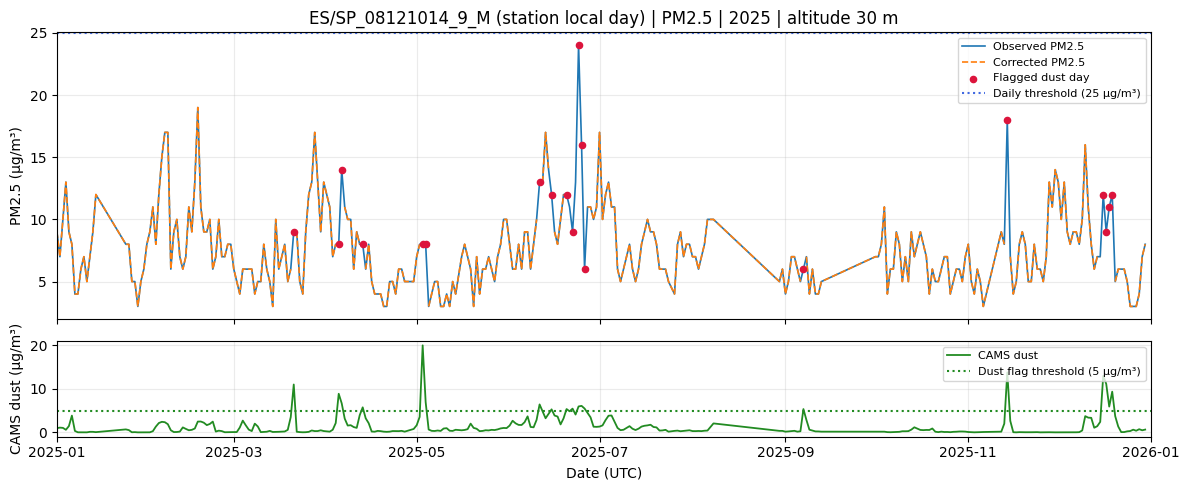

In [45]:
# @title
########### USER INPUT ##############
stations = station_table['Samplingpoint'].unique()
station_name = stations[25] # specify station to plot
#####################################
# Plot timeseries for this station
fig, ax = plot_station_timeseries(
    station_name,
    df_target_year,
    year = YEAR,
    time_column = 'day',
    observed_pollutant_col= 'daily_mean',
    corrected_pollutant_col= 'corrected_pollutant',
    exceedance_threshold= POLLUTANT_daily_threshold,
    cams_dust_threshold= CAMS_dust_threshold,
    pollutant=POLLUTANT
)

### **8.3 Static Map exceedance days**

These maps show the station results as static plots. You can chose the column to plot from the station table.  In the *Edit here* block (next cell), set `columns_to_plot` to one or more of the following columns of the station table:


<center>

| Column | What it shows | Unit |
|:---|:---|:---|
| **Average_pollutant** | Measured annual mean concentration | µg/m³ |
| **Average_pollutant_dust_removed** | Annual mean concentration after subtracting natural dust | µg/m³ |
| **Exceedance_days** | Number of days above the limit value | days |
| **Dust_exceedance_days** | Number of exceedances attributed to natural dust | days |
| **NonDust_exceedance** | Number of exceedances remaining after subtracting natural dust | days |


</center>

Give one title per column in `titles`, and only combine columns with the same unit in one plot, since they share the same colour scale (`vmax_value`). For other colour schemes, see the [Matplotlib colormap reference](https://matplotlib.org/stable/gallery/color/colormap_reference.html).

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_lakes.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


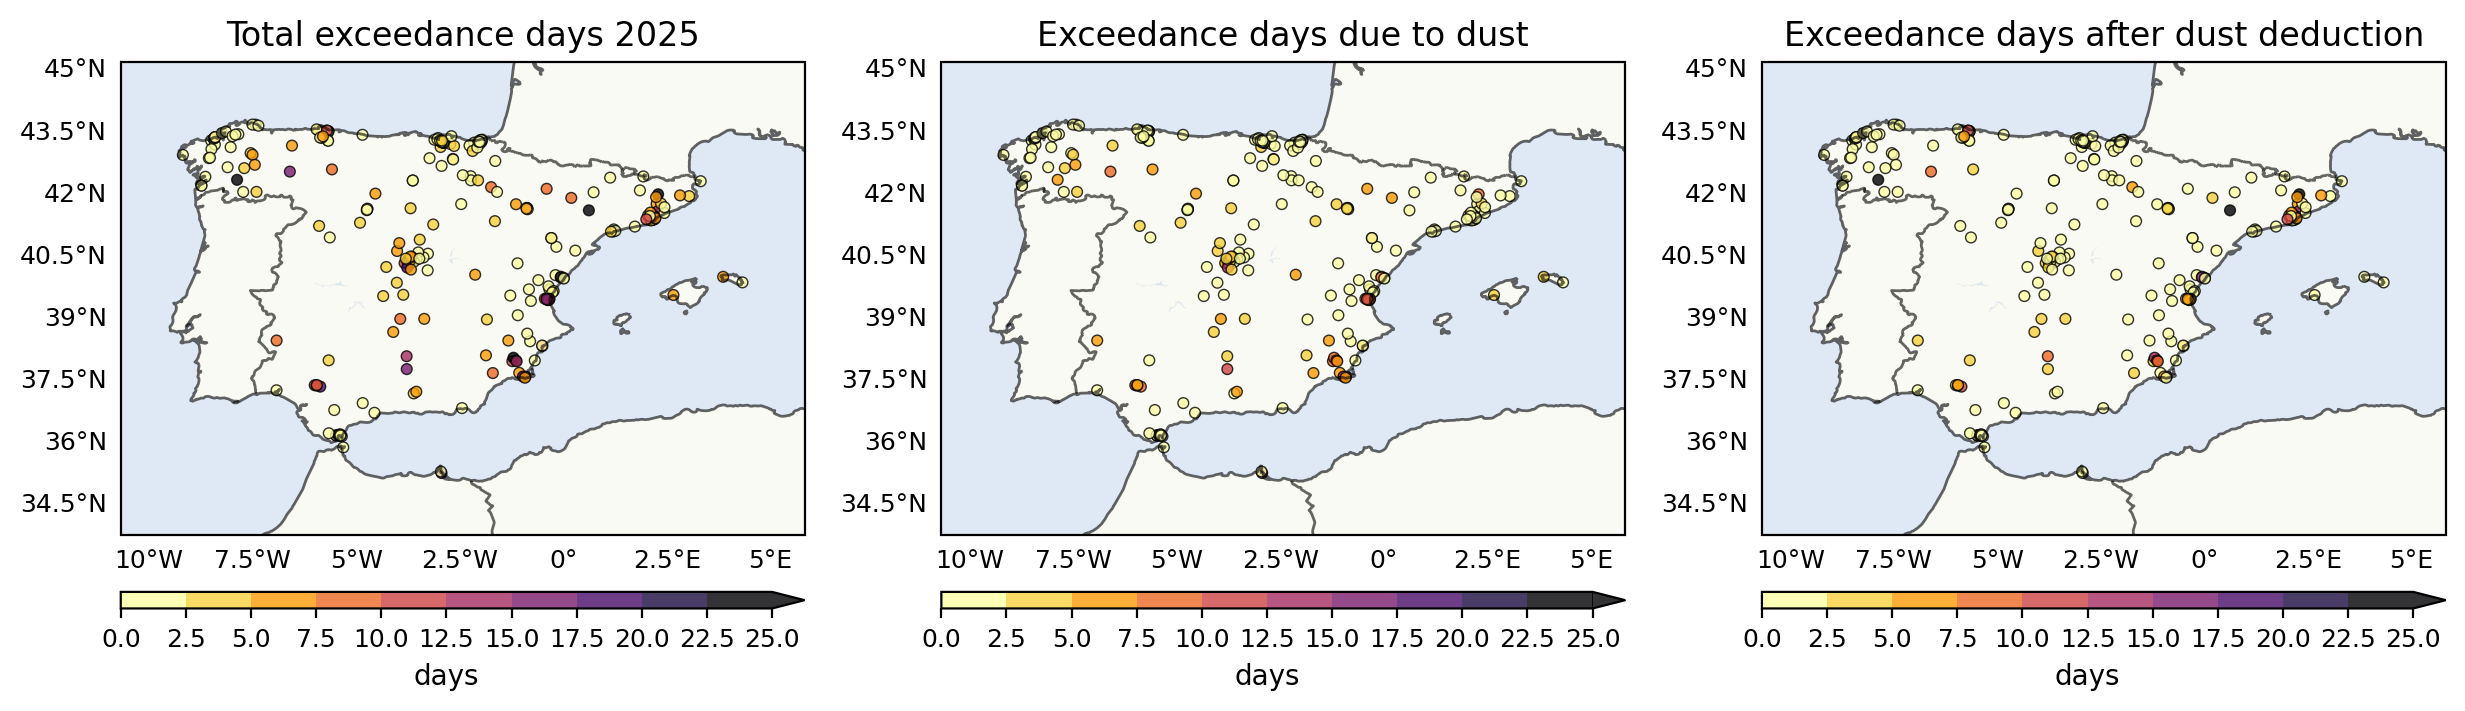

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
# Removed: from mpl_toolkits.axes_grid1 import make_axes_locatable (not needed for the fix)
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from typing import List, Optional, Literal, Sequence, Tuple


def plot_exceedance_maps_discrete(
    df: pd.DataFrame,
    columns_to_plot: Sequence[str],
    titles: Sequence[str],
    vmax: float,
    cbar_text: str,
    cmap_name: str = "gist_heat_r",
    n_colors: int = 10,
    extent: Optional[List[float]] = None,
    gridline : bool = False ,
    # --- NEW OPTIONS ---
    cbar_mode: Literal["single", "each"] = "single",
    cbar_orientation: Literal["vertical", "horizontal"] = "vertical",
    cbar_tick_mode: Literal["bounds", "centers"] = "bounds",
    cbar_size: str = "2.0%",     # only used when cbar_mode='each'
    cbar_pad: str = "1.5%",      # only used when cbar_mode='each'
    cbar_shrink: float = 0.85,   # used for cbar_mode='single'
    cbar_pad_single: float = 0.05,
    marker_size: float = 15,
    marker_alpha: float = 0.8,
    edgecolor: str = "black",
    edge_lw: float = 0.5,
    coast_alpha: float = 0.6,
    borders_alpha: float = 0.6,
    land_alpha: float = 0.3,
    ocean_alpha: float = 0.3,
    lakes_alpha: float = 0.3,
    title_fontsize: int = 12,
    label_fontsize: int = 9,
    figsize_per_panel: Tuple[float, float] = (5.0, 6.0),
    show: bool = True,
    savefile: Optional[str] = None,
    dpi: int = 200,
):
    """
    Plot maps of exceedance data with discrete color levels and flexible colorbar options.

    Parameters
    ----------
    df : DataFrame
        Must contain 'Latitude', 'Longitude', and columns in `columns_to_plot`.
    columns_to_plot : list[str]
        Column names in df to plot.
    titles : list[str]
        Titles for each subplot.
    vmax : float
        Upper bound for the discrete color scale (lower bound is 0).
    cbar_text : str
        Colorbar label text.
    cmap_name : str
        Matplotlib colormap name, e.g., 'gist_heat_r'.
    n_colors : int
        Number of discrete levels (creates n_colors+1 boundaries from 0..vmax).
    extent : [min_lon, max_lon, min_lat, max_lat] or None
        Map extent. If None, computed dynamically from df with a small buffer.

    Notes
    -----
    - `cbar_mode="single"`: one shared colorbar spanning all axes (fig.colorbar).
    - `cbar_mode="each"`: a separate narrow colorbar per subplot,
      attached via axes_grid1's `make_axes_locatable`.
    - `cbar_orientation` applies to both modes ('vertical' or 'horizontal').
    """
    assert len(columns_to_plot) == len(titles), "Number of columns must match number of titles."

    # --- Discrete colormap & normalization ---
    cmap = plt.get_cmap(cmap_name, n_colors)
    bounds = np.linspace(0, vmax, n_colors + 1)
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    # --- Figure & axes ---
    n_panels = len(columns_to_plot)
    fig_w = figsize_per_panel[0] * n_panels
    fig_h = figsize_per_panel[1]
    fig, axs = plt.subplots(
        1, n_panels,
        figsize=(fig_w, fig_h),
        subplot_kw={"projection": ccrs.PlateCarree()},
        dpi=dpi
    )

    # Ensure axs is iterable for 1 panel
    if n_panels == 1:
        axs = [axs]

    scatters = []

    # --- Plot each panel ---
    for i, (col, title) in enumerate(zip(columns_to_plot, titles)):
        ax = axs[i]

        # Scatter
        sc = ax.scatter(
            df["Longitude"], df["Latitude"],
            c=df[col],
            s=marker_size, cmap=cmap, norm=norm,
            transform=ccrs.PlateCarree(),
            alpha=marker_alpha, edgecolors=edgecolor, linewidth=edge_lw
        )
        scatters.append(sc)

        # Map features
        ax.add_feature(cfeature.COASTLINE, alpha=coast_alpha)
        ax.add_feature(cfeature.BORDERS, alpha=borders_alpha)
        ax.add_feature(cfeature.LAND, alpha=land_alpha)
        ax.add_feature(cfeature.OCEAN, alpha=ocean_alpha)
        ax.add_feature(cfeature.LAKES, alpha=lakes_alpha)

        # Extent
        if extent is None:
            buffer_val = 1.5
            dynamic_extent = [
                df["Longitude"].min() - buffer_val, df["Longitude"].max() + buffer_val,
                df["Latitude"].min() - buffer_val, df["Latitude"].max() + buffer_val
            ]
            ax.set_extent(dynamic_extent, crs=ccrs.PlateCarree())
        else:
            ax.set_extent(extent, crs=ccrs.PlateCarree())


        ax.set_title(title, fontsize=title_fontsize)
        if i == 0 or cbar_mode == "each":
            gl = ax.gridlines(draw_labels=True, dms=False, x_inline=False, y_inline=False)
            gl.top_labels = False
            gl.right_labels = False
            gl.bottom_labels = True
            gl.left_labels = True
            # Hide grid lines (labels only)
            try:
                gl.xlines = gridline
                gl.ylines = gridline
            except Exception:
                pass
            gl.xlabel_style = {"size": label_fontsize}
            gl.ylabel_style = {"size": label_fontsize}
        else:
            gl = ax.gridlines(draw_labels=False, dms=False, x_inline=False, y_inline=False)
            try:
                gl.xlines = gridline
                gl.ylines = gridline
            except Exception:
                pass
    # --- Colorbar ticks: bounds vs centers ---
    if cbar_tick_mode == "bounds":
        ticks = bounds
    elif cbar_tick_mode == "centers":
        ticks = (bounds[:-1] + bounds[1:]) / 2.0
    else:
        raise ValueError("cbar_tick_mode must be 'bounds' or 'centers'.")

    # --- Build colorbar(s) ---
    if cbar_mode == "single":
        # Use a ScalarMappable so the colorbar is independent of a specific artist
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
        sm.set_array([])

        # Choose pad depending on orientation (slightly larger for horizontal)
        pad = cbar_pad_single if cbar_orientation == "vertical" else 0.08

        cbar = fig.colorbar(
            sm, ax=axs, orientation=cbar_orientation,
            shrink=cbar_shrink, pad=pad, ticks=ticks, extend="max", spacing="proportional"
        )
        cbar.set_label(cbar_text, fontsize=label_fontsize + 2)
        cbar.ax.tick_params(labelsize=label_fontsize)


    elif cbar_mode == "each":
        # Manually create and position colorbar axes for 'each' mode to avoid GeoAxes interaction
        for ax, sc in zip(axs, scatters):
            ax_pos = ax.get_position()  # Get the bounding box of the main axis
            cax = None

            # Convert string percentages to floats representing a fraction of the *axis* dimension
            cbar_size_ratio = float(cbar_size.replace('%', '')) / 100.0
            cbar_pad_ratio = float(cbar_pad.replace('%', '')) / 100.0

            if cbar_orientation == "vertical":
                # Calculate position for a vertical colorbar to the right of the main axis
                # x0, y0, width, height for fig.add_axes
                cax_width = ax_pos.width * cbar_size_ratio
                cax_x0 = ax_pos.x1 + (ax_pos.width * cbar_pad_ratio)
                cax_y0 = ax_pos.y0
                cax_height = ax_pos.height

                cax = fig.add_axes([cax_x0, cax_y0, cax_width, cax_height])

            elif cbar_orientation == "horizontal":
                # Calculate position for a horizontal colorbar below the main axis
                cax_height = ax_pos.height * cbar_size_ratio
                cax_y0 = ax_pos.y0 - (ax_pos.height * cbar_pad_ratio) - cax_height
                cax_x0 = ax_pos.x0
                cax_width = ax_pos.width

                cax = fig.add_axes([cax_x0, cax_y0, cax_width, cax_height])

            else:
                raise ValueError("cbar_orientation must be 'vertical' or 'horizontal'.")

            if cax is not None:
                cb = plt.colorbar(
                    sc, cax=cax, orientation=cbar_orientation,
                    ticks=ticks, extend="max", spacing="proportional"
                )
                cb.set_label(cbar_text, fontsize=label_fontsize + 1)
                cb.ax.tick_params(labelsize=label_fontsize)
    else:
        raise ValueError("cbar_mode must be 'single' or 'each'.")

    # Remove tight_layout for 'each' mode as it conflicts with manually placed axes.
    # It is usually still desired for 'single' mode with shared colorbar.
    # if cbar_mode == "single":
    #     # fig.tight_layout()

    if savefile:
        fig.savefig(savefile, bbox_inches="tight", dpi=dpi)

    if show:
        plt.show()
    else:
        plt.close(fig)

###################Edit here#########################
columns_to_plot = ['Exceedance_days', 'Dust_exceedance_days', 'NonDust_exceedance']
titles = [
    f'Total exceedance days {YEAR}',
    'Exceedance days due to dust',
    'Exceedance days after dust deduction'
]

if POLLUTANT.upper() == 'PM10':
    vmax_value = POLLUTANT_daily_threshold
    n_colors = 10
elif POLLUTANT.upper() in ('PM2.5'):
    vmax_value = POLLUTANT_daily_threshold
    n_colors = 10
else:
    raise ValueError(f'Pollutant not supported: {POLLUTANT}')
#vmax_value = max(1, np.ceil(station_table['Average_pollutant'].quantile(0.9)))
#vmax_value = 40
#n_colors = 8
colormap='inferno_r' # see https://matplotlib.org/stable/gallery/color/colormap_reference.html for options, for example Set1 gistheat_r twilight

# Create country prefixes for filtering
country_prefixes = tuple(c + '/' for c in Countries)

# Filter station_table by selected countries
station_table_country = station_table[
    station_table['Samplingpoint'].str.startswith(country_prefixes)
].copy()

###################Stop here#########################
plot_exceedance_maps_discrete(
    station_table_country, columns_to_plot, titles, vmax_value,    # data
    n_colors=n_colors,cbar_text='days',cmap_name=colormap, # color setup
    cbar_mode="each",                                       # color bar location "each" each plot would be a individual plot or "single" for panel plot
    cbar_orientation="horizontal",
    cbar_size="3.5%", cbar_pad="12%"                        # size >3% and pad 12% horizontal

)

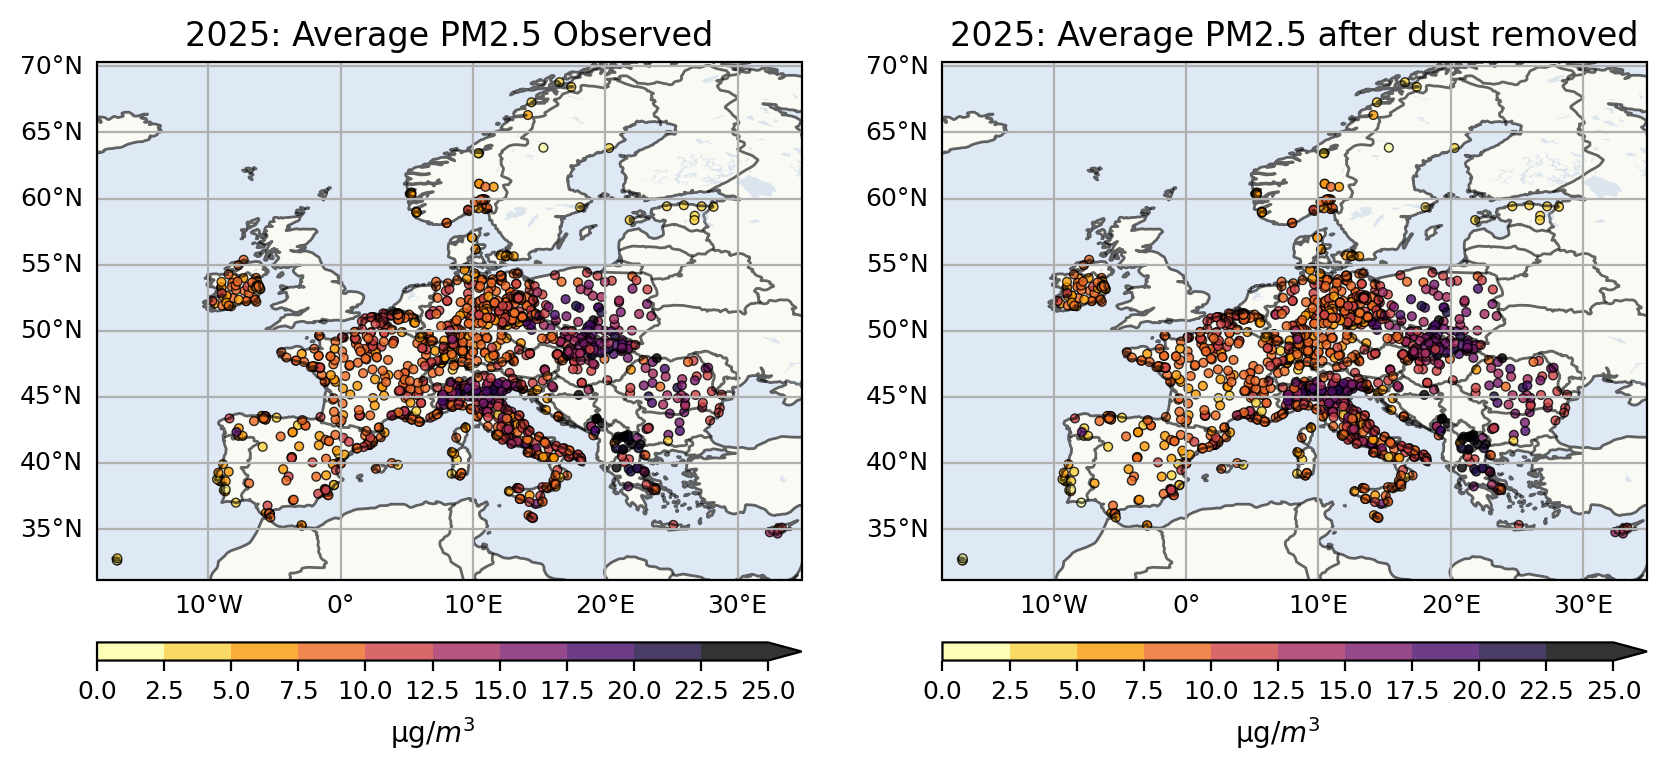

In [ ]:
###################Edit here#########################
columns_to_plot = ['Average_pollutant', 'Average_pollutant_dust_removed']
titles = [
    f'{YEAR}: Average {POLLUTANT} Observed',
    f'{YEAR}: Average {POLLUTANT} after dust removed'
]

if POLLUTANT.upper() == 'PM10':
    vmax_value = POLLUTANT_daily_threshold
    n_colors = 10
elif POLLUTANT.upper() in ('PM2.5'):
    vmax_value = POLLUTANT_daily_threshold
    n_colors = 10
else:
    raise ValueError(f'Pollutant not supported: {POLLUTANT}')

#vmax_value = max(1, np.ceil(station_table['Average_pollutant'].quantile(0.95)))
#vmax_value = 50
#n_colors = 10
colormap='inferno_r'
###################Stop here#########################
plot_exceedance_maps_discrete(station_table, columns_to_plot, titles, vmax_value,
    cbar_mode="each",
    cbar_orientation="horizontal",gridline = True,
    n_colors=n_colors,cbar_text='µg/$m^3$',cmap_name=colormap,
    cbar_size="3.5%", cbar_pad="12%",
    marker_size = 10 )

<a name="8.4"></a>
### **8.4 Exceedance report: what changes after the natural deduction**

These tables and plots summarise, for the selected countries and year, how the natural (dust) deduction changes compliance with the limit values. They answer the questions Member States report on under Article 16:

* **Compliance summary**: how many stations exceed the daily limit value more often than allowed (`ALLOWED_DAILY_EXCEEDANCES`, 18 days per year in Directive (EU) 2024/2881) or exceed the annual limit value, measured and after deduction.
* **Stations that change status**, in two tables: stations that go from more than the allowed number of exceedance days to the allowed number or fewer (daily LV), and stations whose annual mean drops to the annual LV or below (annual LV). `overall_status` tells whether the station then meets both limit values (`met after deduction`) or still exceeds one of them (`still exceeded`). A map shows where these stations are and their class.
* **Per station class** (RB, UB, TH): where the natural contribution has the largest effect.
* **Per month**: when the exceedances attributed to dust happen (seasonality of dust episodes).
* **Main dust episodes**: the days with the most exceedances attributed to natural dust.

All numbers are computed from the daily table (`df_target_year`), using the adjusted value after the deduction.

In [ ]:
###################Edit here#########################
ALLOWED_DAILY_EXCEEDANCES = 18          # days per calendar year above the daily limit value
REPORT_COUNTRIES          = Countries   # e.g. ['ES']
###################Stop here#########################

report_daily = df_target_year[
    df_target_year['Samplingpoint'].astype(str).str.startswith(tuple(c + '/' for c in REPORT_COUNTRIES))
]
# Station class (RB/UB/TH) and coordinates come from the pairing table of section 7.
if 'station_pairing' in globals():
    report_daily = er.add_station_info(report_daily, station_pairing)
report_stations = er.station_compliance(
    report_daily,
    daily_limit=POLLUTANT_daily_threshold,
    annual_limit=POLLUTANT_annual_threshold,
    allowed_exceedances=ALLOWED_DAILY_EXCEEDANCES,
)
report_summary = er.compliance_summary(report_stations)
report_classes = er.class_summary(report_stations)
report_changes = report_stations[report_stations['status_change'] != '']

print(f'{POLLUTANT} {YEAR}: daily LV {POLLUTANT_daily_threshold} µg/m³ (max {ALLOWED_DAILY_EXCEEDANCES} days), '
      f'annual LV {POLLUTANT_annual_threshold} µg/m³')
display(report_summary)
print('Per station class')
display(report_classes)

daily_changes = report_stations[report_stations['daily_lv_status'] == 'met after deduction']
print(f'\nDaily LV: {len(daily_changes)} station(s) go from more than {ALLOWED_DAILY_EXCEEDANCES} '
      f'exceedance days to {ALLOWED_DAILY_EXCEEDANCES} or fewer after the deduction')
display(daily_changes[['Samplingpoint', 'station_class', 'exceedances_measured', 'exceedances_adjusted',
                       'annual_lv_status', 'overall_status']])

annual_changes = report_stations[report_stations['annual_lv_status'] == 'met after deduction']
print(f'\nAnnual LV: {len(annual_changes)} station(s) go from above {POLLUTANT_annual_threshold} µg/m³ '
      f'to {POLLUTANT_annual_threshold} µg/m³ or below after the deduction')
display(annual_changes[['Samplingpoint', 'station_class', 'annual_mean_measured', 'annual_mean_adjusted',
                        'daily_lv_status', 'overall_status']])

n_compliant = int((report_stations['overall_status'] == 'met after deduction').sum())
print(f'\nOverall: {n_compliant} station(s) meet both limit values only after the deduction')

PM2.5 2025: daily LV 25 µg/m³ (max 18 days), annual LV 10 µg/m³


,indicator,measured,after deduction,change
0,Stations,247.00,247.00,0.00
1,Stations with at least one exceedance day,193.00,138.00,-55.00
2,Stations above the allowed number of exceedanc...,8.00,3.00,-5.00
3,Stations above the annual LV,62.00,43.00,-19.00
4,"Exceedance days, all stations",1064.00,535.00,-529.00
5,Maximum exceedance days at one station,61.00,53.00,-8.00
6,Mean annual concentration (µg/m³),8.62,7.93,-0.69


Per station class


,station_class,stations,exceedances_measured,exceedances_adjusted,exceedances_natural,daily_lv_exceeded_measured,daily_lv_exceeded_adjusted,mean_annual_reduction,share_natural_pct
0,unknown,247,1064,535,529,8,3,0.69279,49.7


24 station(s) change compliance status after the deduction


,Samplingpoint,station_class,exceedances_measured,exceedances_adjusted,annual_mean_measured,annual_mean_adjusted,status_change
2,ES/SP_30030007_9_A (UTC day),unknown,25,14,14.571663,13.365483,daily LV met after deduction
4,ES/SP_30027002_9_A (UTC day),unknown,23,14,12.680456,11.388365,daily LV met after deduction
5,ES/SP_12040016_9_M (station local day),unknown,23,15,15.084337,14.576433,daily LV met after deduction
6,ES/SP_11008008_9_49 (UTC day),unknown,20,11,15.399794,14.613639,daily LV met after deduction
7,ES/SP_30016020_9_A (UTC day),unknown,19,5,11.628633,10.233550,daily LV met after deduction
12,ES/SP_24115017_9_46 (UTC day),unknown,16,8,10.108333,7.713457,annual LV met after deduction
23,ES/SP_28007004_9_49 (UTC day),unknown,11,4,10.852753,9.552941,annual LV met after deduction
26,ES/SP_30005002_9_A (UTC day),unknown,11,3,11.073462,9.702811,annual LV met after deduction
29,ES/SP_13034002_9_49 (UTC day),unknown,9,4,10.223056,8.424929,annual LV met after deduction
32,ES/SP_22158002_9_M (station local day),unknown,9,4,10.435028,9.864062,annual LV met after deduction


**Map of the stations that change status.** Colour = station class (RB green, UB blue, TH red). Shape = which limit value is met only after the deduction: circle = daily LV (number of exceedance days), square = annual LV, star = both. A filled marker means the station meets both limit values after the deduction; a hollow marker means it still exceeds the other one. Grey dots are stations whose status does not change. Stations that change on the daily LV are labelled.

In [ ]:
er.plot_compliance_map(report_stations)
plt.show()

#### **8.4.1 Plots**

1. **Exceedance days per station**: measured (red) and after deduction (blue), with the allowed number of days as a dashed line. Stations whose red bar crosses the line but whose blue bar does not reach compliance only thanks to the deduction.
2. **Exceedances per month**: exceedance days of all stations, split into the part that remains after the deduction and the part attributed to natural dust, with the mean natural contribution on dust days (black line).
3. **Annual mean before and after**: each point is a station; points right of the vertical line and below the horizontal line meet the annual limit value only after the deduction.
4. **Natural contribution per month**: distribution of the quantified natural contribution on confirmed dust days.

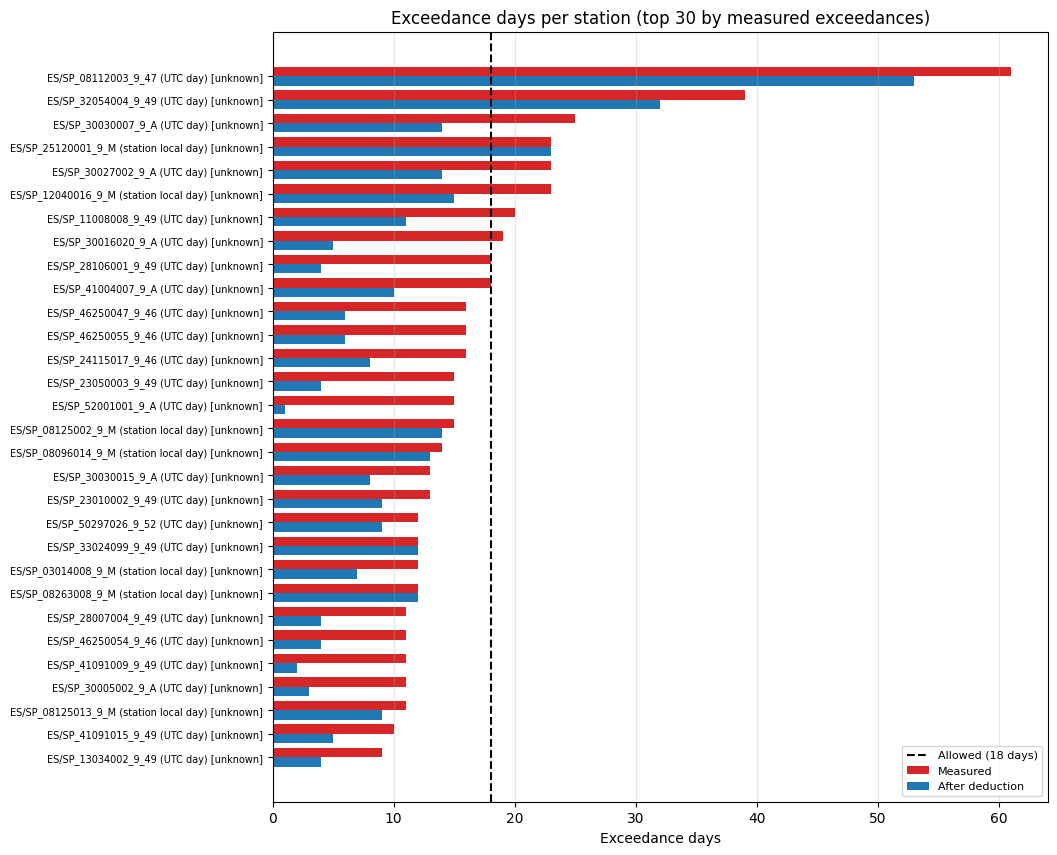

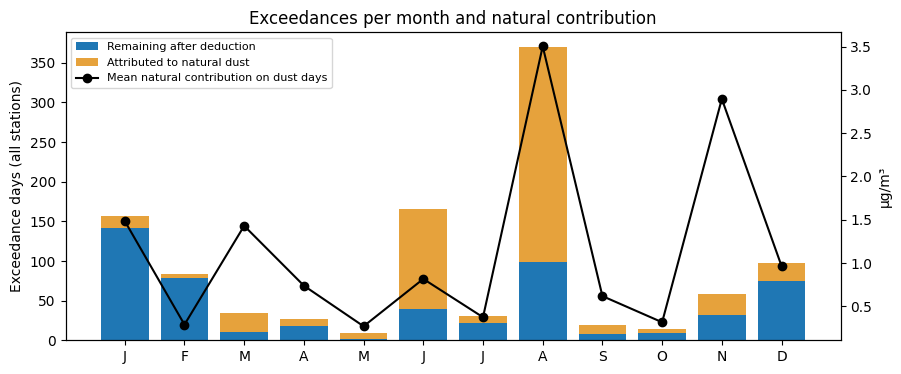

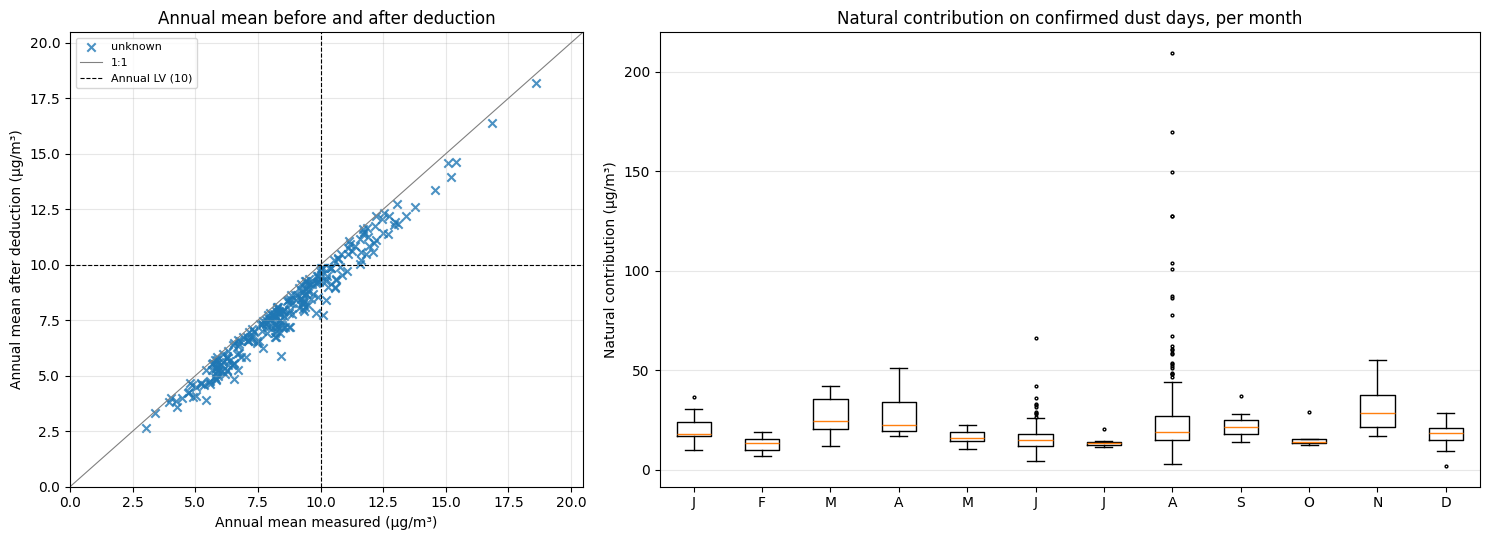

In [48]:
###################Edit here#########################
TOP_STATIONS = 30   # stations shown in the exceedance bar chart
###################Stop here#########################

er.plot_station_exceedances(report_stations, allowed_exceedances=ALLOWED_DAILY_EXCEEDANCES, top=TOP_STATIONS)
plt.show()

report_monthly = er.monthly_summary(report_daily, daily_limit=POLLUTANT_daily_threshold)
er.plot_monthly(report_monthly)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1, 1.6]})
er.plot_annual_means(report_stations, annual_limit=POLLUTANT_annual_threshold, ax=axes[0])
er.plot_contribution_distribution(report_daily, ax=axes[1])
fig.tight_layout()
plt.show()

#### **8.4.2 Main dust episodes and export**

The first table lists the days with the most exceedances attributed to natural dust (number of stations with a CAMS dust flag, exceedances measured, exceedances removed by the deduction, and the largest and mean natural contribution). These are the episodes to document in a natural-contribution report.

The second part writes all report tables as CSV files to the output folder (`{country}_{POLLUTANT}_{YEAR}_report_*.csv`): summary, per class, per station, per month and episodes.

In [49]:
###################Edit here#########################
N_EPISODES   = 15
SAVE_REPORT  = True
###################Stop here#########################

report_episodes = er.episode_table(report_daily, daily_limit=POLLUTANT_daily_threshold, top=N_EPISODES)
display(report_episodes)

if SAVE_REPORT:
    prefix = f"{'_'.join(REPORT_COUNTRIES)}_{POLLUTANT}_{YEAR}_report"
    paths = er.export_tables(
        {
            'summary': report_summary,
            'by_class': report_classes,
            'by_station': report_stations,
            'by_month': report_monthly,
            'episodes': report_episodes,
        },
        OUTPUT_DIR, prefix,
    )
    print('Saved:', *paths, sep='\n  ')

,day,stations_with_dust,exceedances_measured,exceedances_natural,max_contribution,mean_contribution
0,2025-08-17,173,51,50,169.862503,5.658247
1,2025-08-18,119,47,45,77.687500,6.761175
2,2025-08-16,158,36,35,209.541672,4.317818
3,2025-08-19,101,37,22,52.250000,3.322124
4,2025-06-13,100,25,22,22.375000,1.550111
5,2025-06-14,111,21,21,29.000000,1.448394
6,2025-08-26,144,24,20,33.020832,1.892537
7,2025-11-14,94,19,19,55.000000,2.740941
8,2025-08-11,148,18,18,58.291668,1.484484
9,2025-08-15,115,21,16,127.812508,3.407444


Saved:
  /content/drive/MyDrive/CAMS_Tool_output/ES_PM2.5_2025_report_summary.csv
  /content/drive/MyDrive/CAMS_Tool_output/ES_PM2.5_2025_report_by_class.csv
  /content/drive/MyDrive/CAMS_Tool_output/ES_PM2.5_2025_report_by_station.csv
  /content/drive/MyDrive/CAMS_Tool_output/ES_PM2.5_2025_report_by_month.csv
  /content/drive/MyDrive/CAMS_Tool_output/ES_PM2.5_2025_report_episodes.csv
